# **CINEMA AUDIENCE FORECASTING - TIME SERIES PREDICTION**

## **This notebook predicts future daily theatre audience counts across multiple locations.**

### The data comes from two separate booking platforms:
### 1. BookNow: an online booking and aggregation platform where users can search theatres and book tickets in advance.
### 2. CinePOS: a point-of-sale (POS) system installed at theaters that tracks on-site ticket sales.


## Dataset Description

***
* cinePOS_theaters.csv – CinePOS theatre metadata
* booknow_theaters.csv – BookNow theatre metadata
* movie_theater_id_relation.csv – Mapping between BookNow and CinePOS theaters
* cinePOS_booking.csv – CinePOS bookings
* booknow_booking.csv – BookNow bookings
* booknow_visits.csv – Daily audience counts
* date_info.csv – Calendar information
* sample_submission.csv – Submission format (ID = book_theater_id + show_date, audience_count)
***

# Environment Setup

In [1]:
# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings("ignore")

In [2]:
# Install specific sklearn version for compatibility
!pip install scikit-learn==1.7.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 87.5 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.2.2
    Uninstalling scikit-learn-1.2.2:
      Successfully uninstalled scikit-learn-1.2.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
category-encoders 2.7.0 requires scikit-learn<1.6.0,>=1.0.0, but you have scikit-learn 1.7.0 which is incompatible.
cesium 0.12.4 requires numpy<3.0,>=2.0, but you have numpy 1.26.4 which is incompatible.
sklearn-compat 0.1.3 requires scikit-learn<1.7,>=1.2, but you have scikit-learn 1.7.0 which is incompatible.


In [3]:
# Verify sklearn version
import sklearn
print(sklearn.__version__)

1.7.0


# Libraries

In [4]:
# Data manipulation and analysis
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning models
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# Preprocessing and pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import TargetEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Evaluation metrics
from sklearn.metrics import r2_score

# Datasets

## Load Dataset

In [ ]:
# Load all data files from the competition dataset
cinePOS_theaters = pd.read_csv("cinePOS_theaters.csv")
booknow_theaters = pd.read_csv("booknow_theaters.csv")
movie_theater_id_relation = pd.read_csv("movie_theater_id_relation.csv")
cinePOS_booking = pd.read_csv("cinePOS_booking.csv")
booknow_booking = pd.read_csv("booknow_booking.csv")
booknow_visits = pd.read_csv("booknow_visits.csv")
date_info = pd.read_csv("date_info.csv")
sample_submission = pd.read_csv("sample_submission.csv")

## Sample Dataset

In [6]:
# CinePOS theatre metadata
cinePOS_theaters.head()

,cine_theater_id,theater_type,theater_area,latitude,longitude
0,cinePOS_05466,Other,Area_104,22.619233,78.113017
1,cinePOS_08708,Other,Area_104,22.619233,78.113017
2,cinePOS_00753,Other,Area_104,22.619233,78.113017
3,cinePOS_05776,Other,Area_104,22.619233,78.113017
4,cinePOS_07536,Other,Area_104,23.004410,79.934515


In [7]:
# BookNow theatre metadata
booknow_theaters.head()

,book_theater_id,theater_type,theater_area,latitude,longitude
0,book_00093,Drama,Area_001,22.619233,78.113017
1,book_00078,Drama,Area_001,22.619233,78.113017
2,book_00291,Drama,Area_001,22.619233,78.113017
3,book_00258,Drama,Area_001,22.619233,78.113017
4,book_00212,Drama,Area_002,23.004410,79.934515


In [8]:
# Mapping between BookNow and CinePOS theaters
movie_theater_id_relation.head()

,book_theater_id,cine_theater_id
0,book_00509,cinePOS_01261
1,book_00063,cinePOS_02467
2,book_00054,cinePOS_08923
3,book_00094,cinePOS_02479
4,book_00052,cinePOS_06750


In [9]:
# CinePOS bookings
cinePOS_booking.head()

,cine_theater_id,show_datetime,booking_datetime,tickets_sold
0,cinePOS_00001,2023-01-01 11:00:00,2023-01-01 09:00:00,1
1,cinePOS_00002,2023-01-01 13:00:00,2023-01-01 06:00:00,3
2,cinePOS_00003,2023-01-01 16:00:00,2023-01-01 14:00:00,2
3,cinePOS_00004,2023-01-01 17:00:00,2023-01-01 11:00:00,5
4,cinePOS_00005,2023-01-01 17:00:00,2023-01-01 03:00:00,13


In [10]:
# BookNow bookings
booknow_booking.head()

,book_theater_id,show_datetime,booking_datetime,tickets_booked
0,book_00244,2023-01-01 19:00:00,2023-01-01 16:00:00,1
1,book_00740,2023-01-01 19:00:00,2023-01-01 19:00:00,3
2,book_00740,2023-01-01 19:00:00,2023-01-01 19:00:00,6
3,book_00244,2023-01-01 20:00:00,2023-01-01 16:00:00,2
4,book_00151,2023-01-01 20:00:00,2023-01-01 01:00:00,5


In [11]:
# Daily audience counts
booknow_visits.head()

,book_theater_id,show_date,audience_count
0,book_00001,2023-01-13,50
1,book_00001,2023-01-14,64
2,book_00001,2023-01-15,58
3,book_00001,2023-01-16,44
4,book_00001,2023-01-18,12


In [12]:
# Calendar information
date_info.head()

,show_date,day_of_week
0,2023-01-01,Sunday
1,2023-01-02,Monday
2,2023-01-03,Tuesday
3,2023-01-04,Wednesday
4,2023-01-05,Thursday


In [13]:
# Submission format (ID = book_theater_id + show_date, audience_count)
sample_submission.head()

,ID,audience_count
0,book_00001_2024-03-01,0
1,book_00001_2024-03-02,0
2,book_00001_2024-03-03,0
3,book_00001_2024-03-04,0
4,book_00001_2024-03-06,0


## Dataset Information

In [14]:
# Quick snapshot of all datasets
print("CinePOS theatre info:")
cinePOS_theaters.info()
print("\nBookNow theatre info:")
booknow_theaters.info()
print("\nMapping between BookNow and CinePOS theatres:")
movie_theater_id_relation.info()
print("\nCinePOS bookings:")
cinePOS_booking.info()
print("\nBookNow bookings:")
booknow_booking.info()
print("\nDaily audience counts:")
booknow_visits.info()
print("\nCalendar info:")
date_info.info()
print("\nSubmission Sample:")
sample_submission.info()

CinePOS theatre info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4690 entries, 0 to 4689
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   cine_theater_id  4690 non-null   object 
 1   theater_type     4690 non-null   object 
 2   theater_area     4690 non-null   object 
 3   latitude         829 non-null    float64
 4   longitude        829 non-null    float64
dtypes: float64(2), object(3)
memory usage: 183.3+ KB

BookNow theatre info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 829 entries, 0 to 828
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   book_theater_id  314 non-null    object 
 1   theater_type     829 non-null    object 
 2   theater_area     829 non-null    object 
 3   latitude         829 non-null    float64
 4   longitude        829 non-null    float64
dtypes: float64(2), object(3)
memory usage: 32.

# Dataset Aggregation

### **Combine data from multiple sources into a unified dataset for modeling**

In [ ]:
# Load all data files from the competition dataset
cinePOS_theaters = pd.read_csv("cinePOS_theaters.csv")
booknow_theaters = pd.read_csv("booknow_theaters.csv")
movie_theater_id_relation = pd.read_csv("movie_theater_id_relation.csv")
cinePOS_booking = pd.read_csv("cinePOS_booking.csv")
booknow_booking = pd.read_csv("booknow_booking.csv")
booknow_visits = pd.read_csv("booknow_visits.csv")
date_info = pd.read_csv("date_info.csv")
sample_submission = pd.read_csv("sample_submission.csv")

In [60]:
# Convert datetime columns to proper datetime format
cinePOS_booking['show_datetime'] = pd.to_datetime(cinePOS_booking['show_datetime'])
cinePOS_booking['booking_datetime'] = pd.to_datetime(cinePOS_booking['booking_datetime'])
booknow_booking['show_datetime'] = pd.to_datetime(booknow_booking['show_datetime'])
booknow_booking['booking_datetime'] = pd.to_datetime(booknow_booking['booking_datetime'])
booknow_visits['show_date'] = pd.to_datetime(booknow_visits['show_date'])
date_info['show_date'] = pd.to_datetime(date_info['show_date'])

In [61]:
# Extract date component from datetime for aggregation
booknow_booking['show_date'] = pd.to_datetime(booknow_booking['show_datetime'].dt.date)
cinePOS_booking['show_date'] = pd.to_datetime(cinePOS_booking['show_datetime'].dt.date)

In [62]:
# Aggregate BookNow bookings by theater and date
booknow_daily = (
    booknow_booking.groupby(['book_theater_id', 'show_date'], as_index=False)
    .agg({'tickets_booked': 'sum'})
)
booknow_daily.rename(columns={'tickets_booked': 'booknow_tickets_booked'}, inplace=True)

cinePOS_daily = (
    cinePOS_booking.groupby(['cine_theater_id', 'show_date'], as_index=False)
    .agg({'tickets_sold': 'sum'})
)
cinePOS_daily.rename(columns={'tickets_sold': 'cinePOS_tickets_sold'}, inplace=True)

In [63]:
# Map CinePOS theater IDs to BookNow theater IDs
cinePOS_daily = cinePOS_daily.merge(
    movie_theater_id_relation, on='cine_theater_id', how='left'
)

# Aggregate CinePOS data to BookNow theater level
cinePOS_daily = (
    cinePOS_daily.groupby(['book_theater_id', 'show_date'], as_index=False)
    .agg({'cinePOS_tickets_sold': 'sum'})
)

In [64]:
# Create master dataset by merging all sources
dataset = booknow_visits.copy()
dataset = (
    dataset
    .merge(booknow_daily, on=['book_theater_id', 'show_date'], how='left')
    .merge(cinePOS_daily, on=['book_theater_id', 'show_date'], how='left')
    .merge(booknow_theaters, on='book_theater_id', how='left')
    .merge(date_info, on='show_date', how='left')
)

In [65]:
'''
dataset_raw = dataset.copy()
'''

'\ndataset_raw = dataset.copy()\n'

# Feature Engineering

### **Create time-based, lag, and rolling features for modeling**

In [66]:
# Sort by theater and date for proper time series feature generation
dataset = dataset.sort_values(['book_theater_id', 'show_date']).reset_index(drop=True)

In [67]:
# Time-based features

# Extract calendar components
dataset['year'] = dataset['show_date'].dt.year
dataset['month'] = dataset['show_date'].dt.month
dataset['day'] = dataset['show_date'].dt.day
dataset['weekday'] = dataset['show_date'].dt.weekday # 0=Monday, 6=Sunday
dataset['is_weekend'] = dataset['weekday'].isin([5,6]).astype(int)
dataset['week_of_year'] = dataset['show_date'].dt.isocalendar().week.astype(int)
dataset['quarter'] = dataset['show_date'].dt.quarter
dataset['week_of_month'] = dataset['show_date'].apply(lambda d: (d.day-1)//7 + 1)
dataset['is_month_start'] = dataset['show_date'].dt.is_month_start.astype(int)
dataset['is_month_end'] = dataset['show_date'].dt.is_month_end.astype(int)
dataset['day_of_year'] = dataset['show_date'].dt.dayofyear

# Create cyclical encodings for better capture of periodic patterns
dataset['sin_day']  = np.sin(2 * np.pi * dataset['day_of_year'] / 365)
dataset['cos_day']  = np.cos(2 * np.pi * dataset['day_of_year'] / 365)
dataset['sin_week'] = np.sin(2 * np.pi * dataset['weekday'] / 7)
dataset['cos_week'] = np.cos(2 * np.pi * dataset['weekday'] / 7)

In [68]:
# Lag features

# Previous audience counts at various time intervals
dataset['audience_lag_1'] = dataset.groupby('book_theater_id')['audience_count'].shift(1).fillna(0)
dataset['audience_lag_7'] = dataset.groupby('book_theater_id')['audience_count'].shift(7).fillna(0)
dataset['audience_lag_14'] = dataset.groupby('book_theater_id')['audience_count'].shift(14).fillna(0)
dataset['audience_lag_30'] = dataset.groupby('book_theater_id')['audience_count'].shift(30).fillna(0)

In [69]:
# Rolling window features

# Moving averages to capture trends
dataset['audience_rolling_3'] = dataset.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(3).mean().fillna(0))
dataset['audience_rolling_7'] = dataset.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(7).mean().fillna(0))
dataset['audience_rolling_14'] = dataset.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(14).mean().fillna(0))
dataset['audience_rolling_30'] = dataset.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(30).mean().fillna(0))

In [70]:
# Variability features

# Rolling standard deviation to capture volatility
dataset['audience_std_7'] = dataset.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(7).std().fillna(0))
dataset['audience_std_14'] = dataset.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(14).std().fillna(0))
dataset['audience_std_30'] = dataset.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(30).std().fillna(0))

# Coefficient of variation (normalized volatility)
dataset['audience_cv_7'] = dataset['audience_std_7'] / (dataset['audience_rolling_7'] + 1)
dataset['audience_cv_14'] = dataset['audience_std_14'] / (dataset['audience_rolling_14'] + 1)
dataset['audience_cv_30'] = dataset['audience_std_30'] / (dataset['audience_rolling_30'] + 1)

# Dataset Summary

In [71]:
# Shape of dataset
dataset.shape

(214046, 39)

In [72]:
# Dataset snapshot
dataset.head()

,book_theater_id,show_date,audience_count,booknow_tickets_booked,cinePOS_tickets_sold,theater_type,theater_area,latitude,longitude,day_of_week,...,audience_rolling_3,audience_rolling_7,audience_rolling_14,audience_rolling_30,audience_std_7,audience_std_14,audience_std_30,audience_cv_7,audience_cv_14,audience_cv_30
0,book_00001,2023-01-13,50,NaN,NaN,Drama,Area_002,23.00441,79.934515,Friday,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,book_00001,2023-01-14,64,NaN,NaN,Drama,Area_002,23.00441,79.934515,Saturday,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,book_00001,2023-01-15,58,NaN,NaN,Drama,Area_002,23.00441,79.934515,Sunday,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,book_00001,2023-01-16,44,NaN,NaN,Drama,Area_002,23.00441,79.934515,Monday,...,57.333333,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,book_00001,2023-01-18,12,NaN,NaN,Drama,Area_002,23.00441,79.934515,Wednesday,...,55.333333,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [73]:
# Dataset information
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214046 entries, 0 to 214045
Data columns (total 39 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   book_theater_id         214046 non-null  object        
 1   show_date               214046 non-null  datetime64[ns]
 2   audience_count          214046 non-null  int64         
 3   booknow_tickets_booked  21041 non-null   float64       
 4   cinePOS_tickets_sold    11150 non-null   float64       
 5   theater_type            80150 non-null   object        
 6   theater_area            80150 non-null   object        
 7   latitude                80150 non-null   float64       
 8   longitude               80150 non-null   float64       
 9   day_of_week             214046 non-null  object        
 10  year                    214046 non-null  int32         
 11  month                   214046 non-null  int32         
 12  day                     214046

In [74]:
# Missing values in dataset
dataset.isnull().sum()

book_theater_id                0
show_date                      0
audience_count                 0
booknow_tickets_booked    193005
cinePOS_tickets_sold      202896
theater_type              133896
theater_area              133896
latitude                  133896
longitude                 133896
day_of_week                    0
year                           0
month                          0
day                            0
weekday                        0
is_weekend                     0
week_of_year                   0
quarter                        0
week_of_month                  0
is_month_start                 0
is_month_end                   0
day_of_year                    0
sin_day                        0
cos_day                        0
sin_week                       0
cos_week                       0
audience_lag_1                 0
audience_lag_7                 0
audience_lag_14                0
audience_lag_30                0
audience_rolling_3             0
audience_r

In [75]:
# Descriptive statistics of dataset
dataset.describe(include="all")

,book_theater_id,show_date,audience_count,booknow_tickets_booked,cinePOS_tickets_sold,theater_type,theater_area,latitude,longitude,day_of_week,...,audience_rolling_3,audience_rolling_7,audience_rolling_14,audience_rolling_30,audience_std_7,audience_std_14,audience_std_30,audience_cv_7,audience_cv_14,audience_cv_30
count,214046,214046,214046.000000,21041.000000,11150.000000,80150,80150,80150.000000,80150.000000,214046,...,214046.000000,214046.000000,214046.000000,214046.000000,214046.000000,214046.000000,214046.000000,214046.000000,214046.000000,214046.000000
unique,826,NaN,NaN,NaN,NaN,4,71,NaN,NaN,7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,book_00528,NaN,NaN,NaN,NaN,Other,Area_003,NaN,NaN,Saturday,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,424,NaN,NaN,NaN,NaN,44618,5339,NaN,NaN,33875,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,2023-09-13 04:07:24.285807360,41.616568,13.675776,6.704215,NaN,NaN,23.108170,78.936323,NaN,...,41.141418,40.483010,39.365437,36.865326,19.379297,19.255278,18.424491,0.479257,0.475650,0.454465
min,NaN,2023-01-01 00:00:00,2.000000,1.000000,1.000000,NaN,NaN,22.025970,76.173250,NaN,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,NaN,2023-07-09 00:00:00,18.000000,5.000000,2.000000,NaN,NaN,22.613688,77.970347,NaN,...,20.666667,21.714286,21.142857,18.800000,10.244627,10.675020,9.989420,0.337944,0.356214,0.349483
50%,NaN,2023-09-25 00:00:00,34.000000,10.000000,4.000000,NaN,NaN,23.004410,79.895175,NaN,...,35.333333,36.000000,35.428571,33.333333,16.521271,16.887475,16.669954,0.463760,0.470857,0.469274
75%,NaN,2023-12-11 00:00:00,58.000000,18.000000,8.000000,NaN,NaN,23.018784,79.935314,NaN,...,56.000000,55.714286,55.285714,54.133333,25.237916,25.391874,25.273584,0.600346,0.590495,0.584305
max,NaN,2024-02-28 00:00:00,1350.000000,1633.000000,157.000000,NaN,NaN,26.349436,81.743235,NaN,...,493.333333,335.142857,240.857143,171.133333,487.755989,358.813184,259.174649,2.254498,2.717535,2.866240


In [76]:
# Dataset time range
start_date = dataset['show_date'].min()
end_date = dataset['show_date'].max()

print("Dataset date range:", start_date.strftime("%d-%m-%Y"), "to", end_date.strftime("%d-%m-%Y"))

Dataset date range: 01-01-2023 to 28-02-2024


# Exploratory Data Analysis

## Distribution of Audience Count

#### Plot the distribution of the target variable (audience_count)

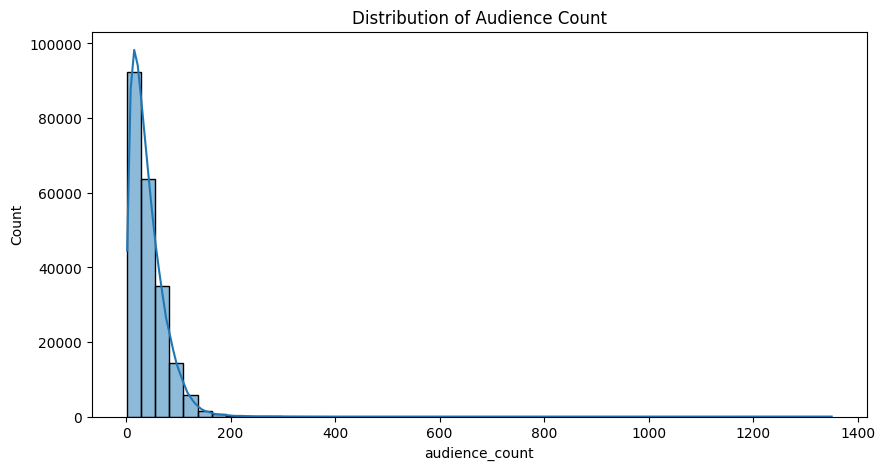

In [77]:
# Set size of the figure
plt.figure(figsize=(10,5))

# Histogram + Kernel Density Estimate (KDE) to visualize distribution & smooth trend
sns.histplot(dataset["audience_count"], bins=50, kde=True)

# Add title
plt.title("Distribution of Audience Count")

# Display the plot
plt.show()

## Average Audience Count for Discrete Features

#### Average audience performance for each category of discrete features

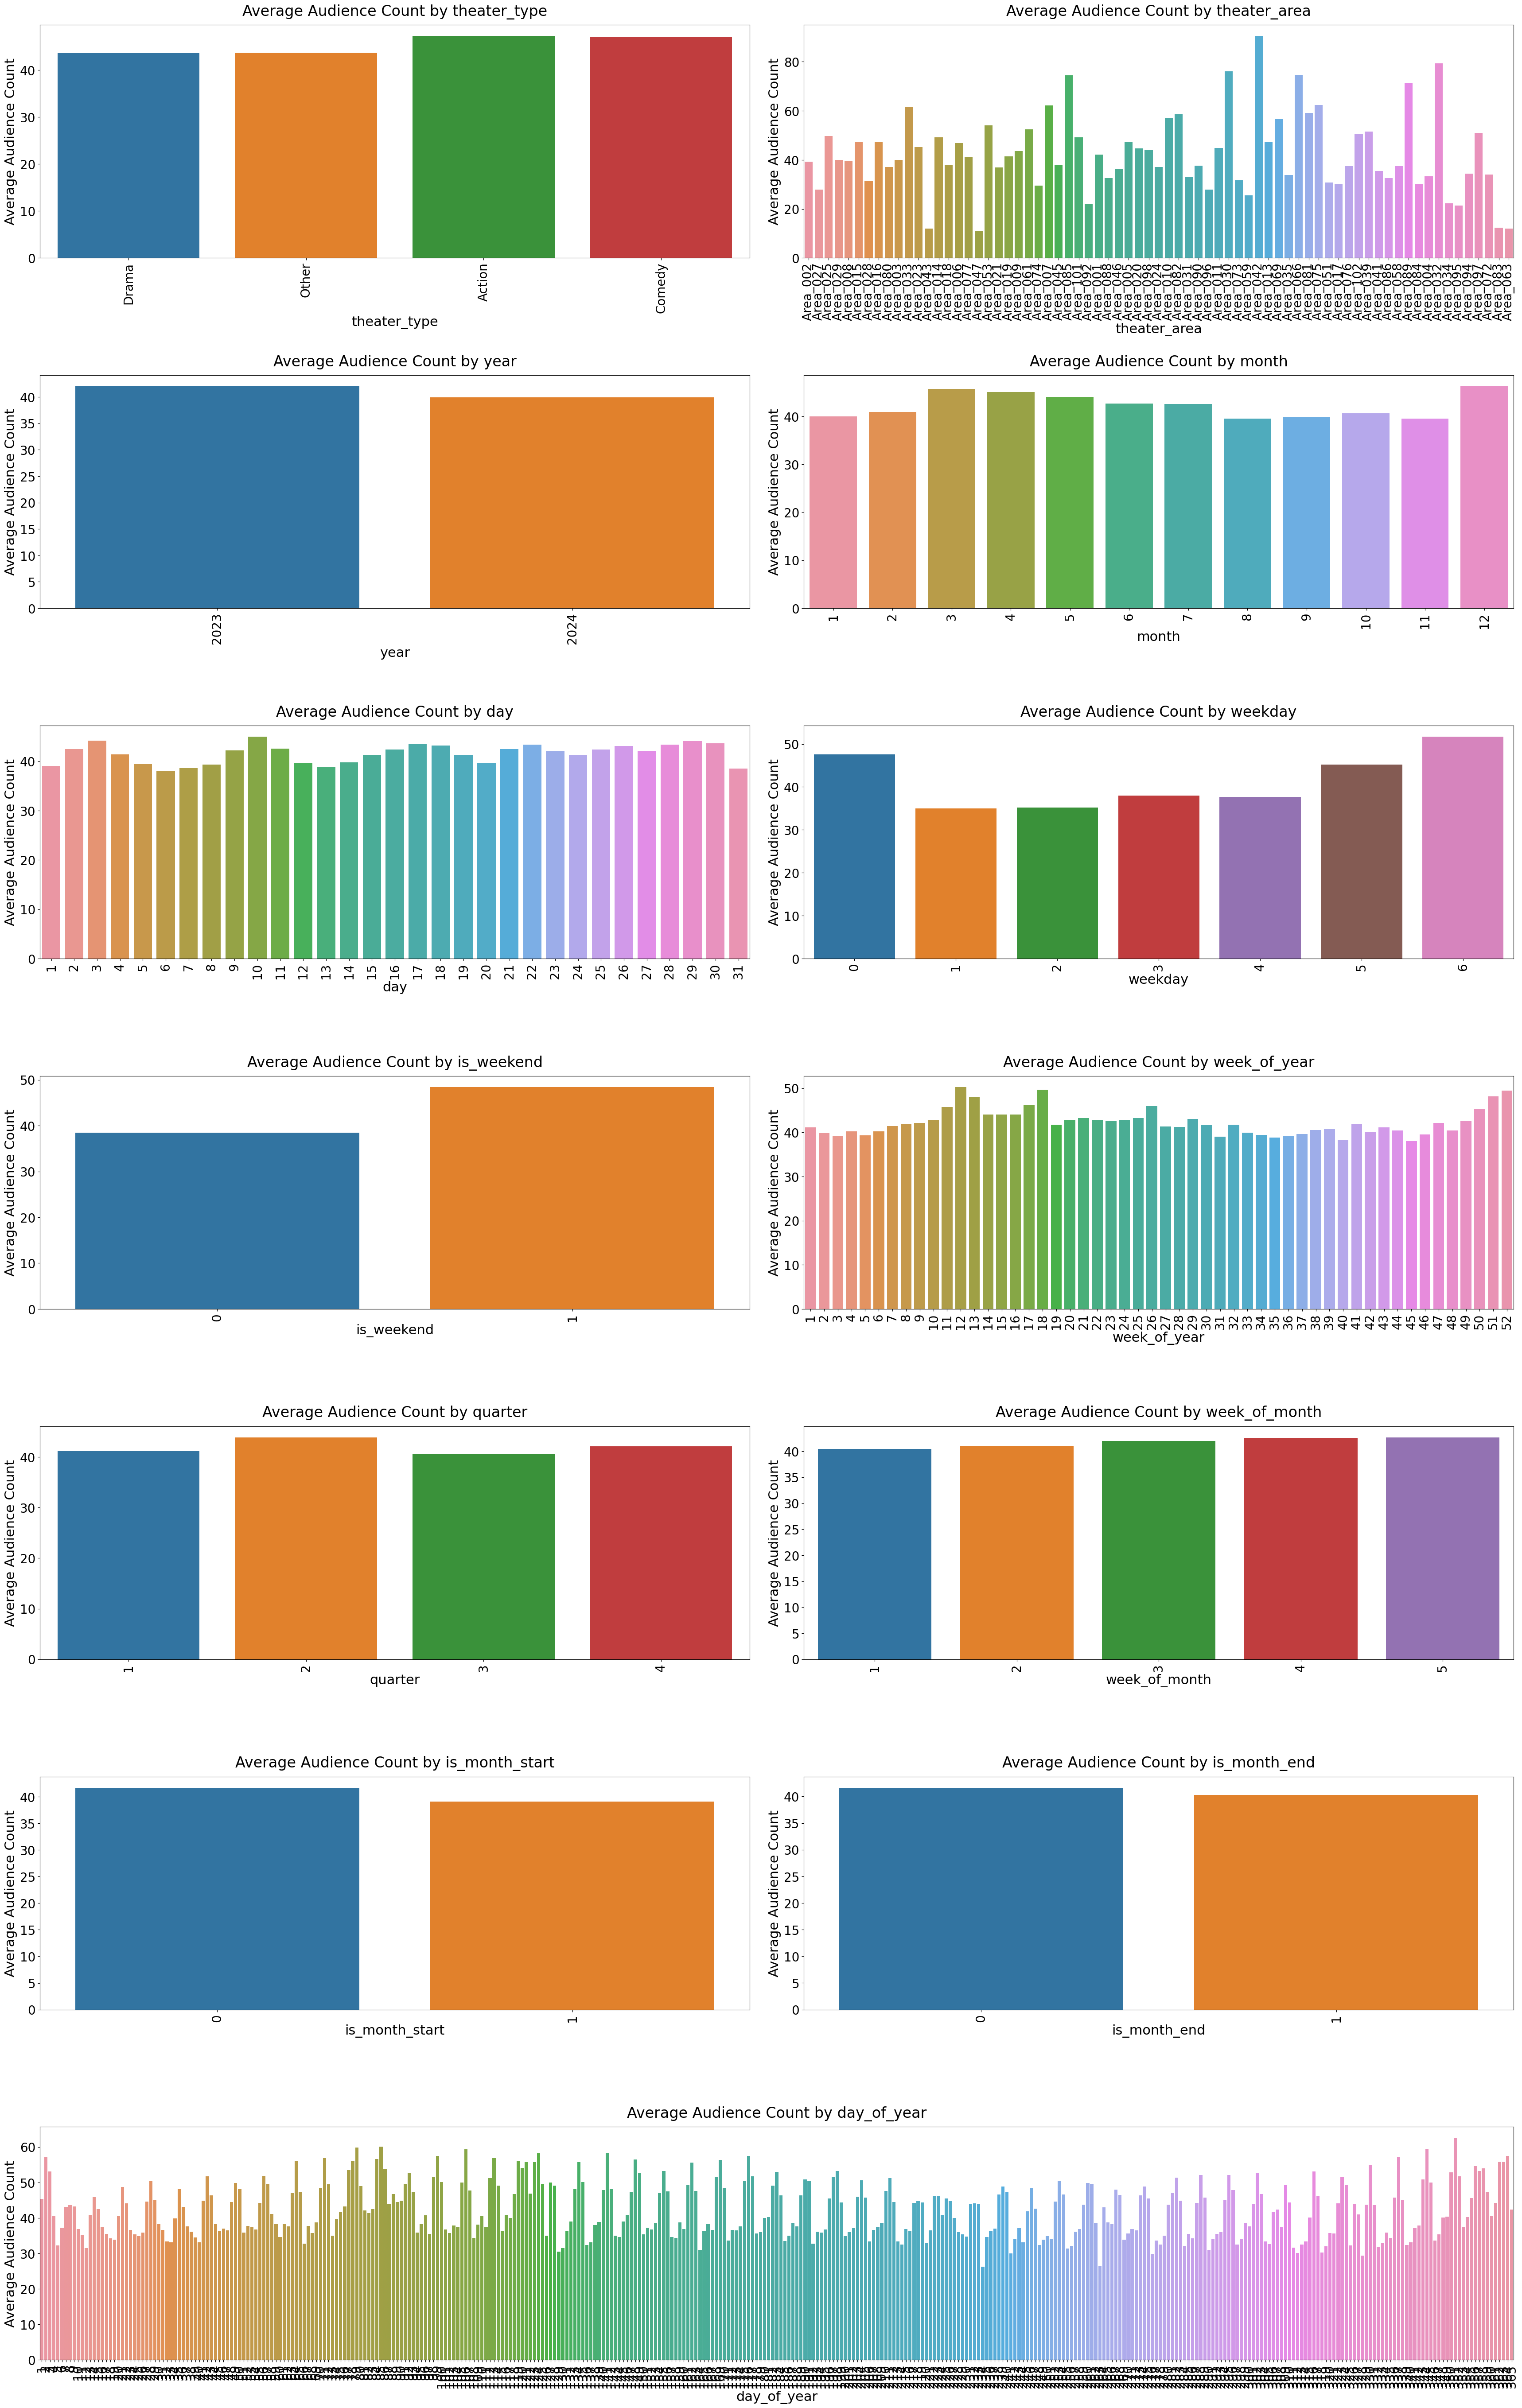

In [78]:
# Discrete features
discrete_cols = ["theater_type", "theater_area", "year","month","day", "weekday", "is_weekend", 
                 "week_of_year", "quarter", "week_of_month", "is_month_start", "is_month_end", "day_of_year"]

# Create a large figure with subplots: 7 rows × 2 columns
fig, axes = plt.subplots(7, 2, figsize=(35, 55))
axes = axes.flatten()  # Flatten so we can index axes easily

# Loop through all columns except the last one, and plot bar charts
for i, col in enumerate(discrete_cols[:-1]):
    ax = axes[i]  # Select subplot
    
    # Bar plot showing average audience_count per category of each feature
    sns.barplot(data=dataset, x=col, y="audience_count", estimator=np.mean, errorbar=None, ax=ax)
    
    # Titles and axis styling
    ax.set_title(f"Average Audience Count by {col}", fontsize=24, pad=15)
    ax.set_xlabel(col, fontsize=22)
    ax.set_ylabel("Average Audience Count", fontsize=22)
    ax.tick_params(axis='x', rotation=90, labelsize=20)
    ax.tick_params(axis='y', labelsize=20)

# Handle the last column separately so it gets a larger subplot
last_col = discrete_cols[-1]

# Remove the last two empty subplots (since we only have 13 columns, not 14)
fig.delaxes(axes[-1])
fig.delaxes(axes[-2])

# Create one big subplot for the last column ("day_of_year")
ax_big = fig.add_subplot(7, 1, 7)

# Bar plot for the final column
sns.barplot(data=dataset, x=last_col, y="audience_count", estimator=np.mean, errorbar=None, ax=ax_big)

# Styling for the last plot
ax_big.set_title(f"Average Audience Count by {last_col}", fontsize=24, pad=15)
ax_big.set_xlabel(last_col, fontsize=22)
ax_big.set_ylabel("Average Audience Count", fontsize=22)
ax_big.tick_params(axis='x', rotation=90, labelsize=20)
ax_big.tick_params(axis='y', labelsize=20)

# Adjust spacing between subplots to prevent overlap
plt.tight_layout(pad=3)

# Display the final figure
plt.show()

## Top Theaters and their Audience Count over time

#### Top 5 theaters and its performance over time

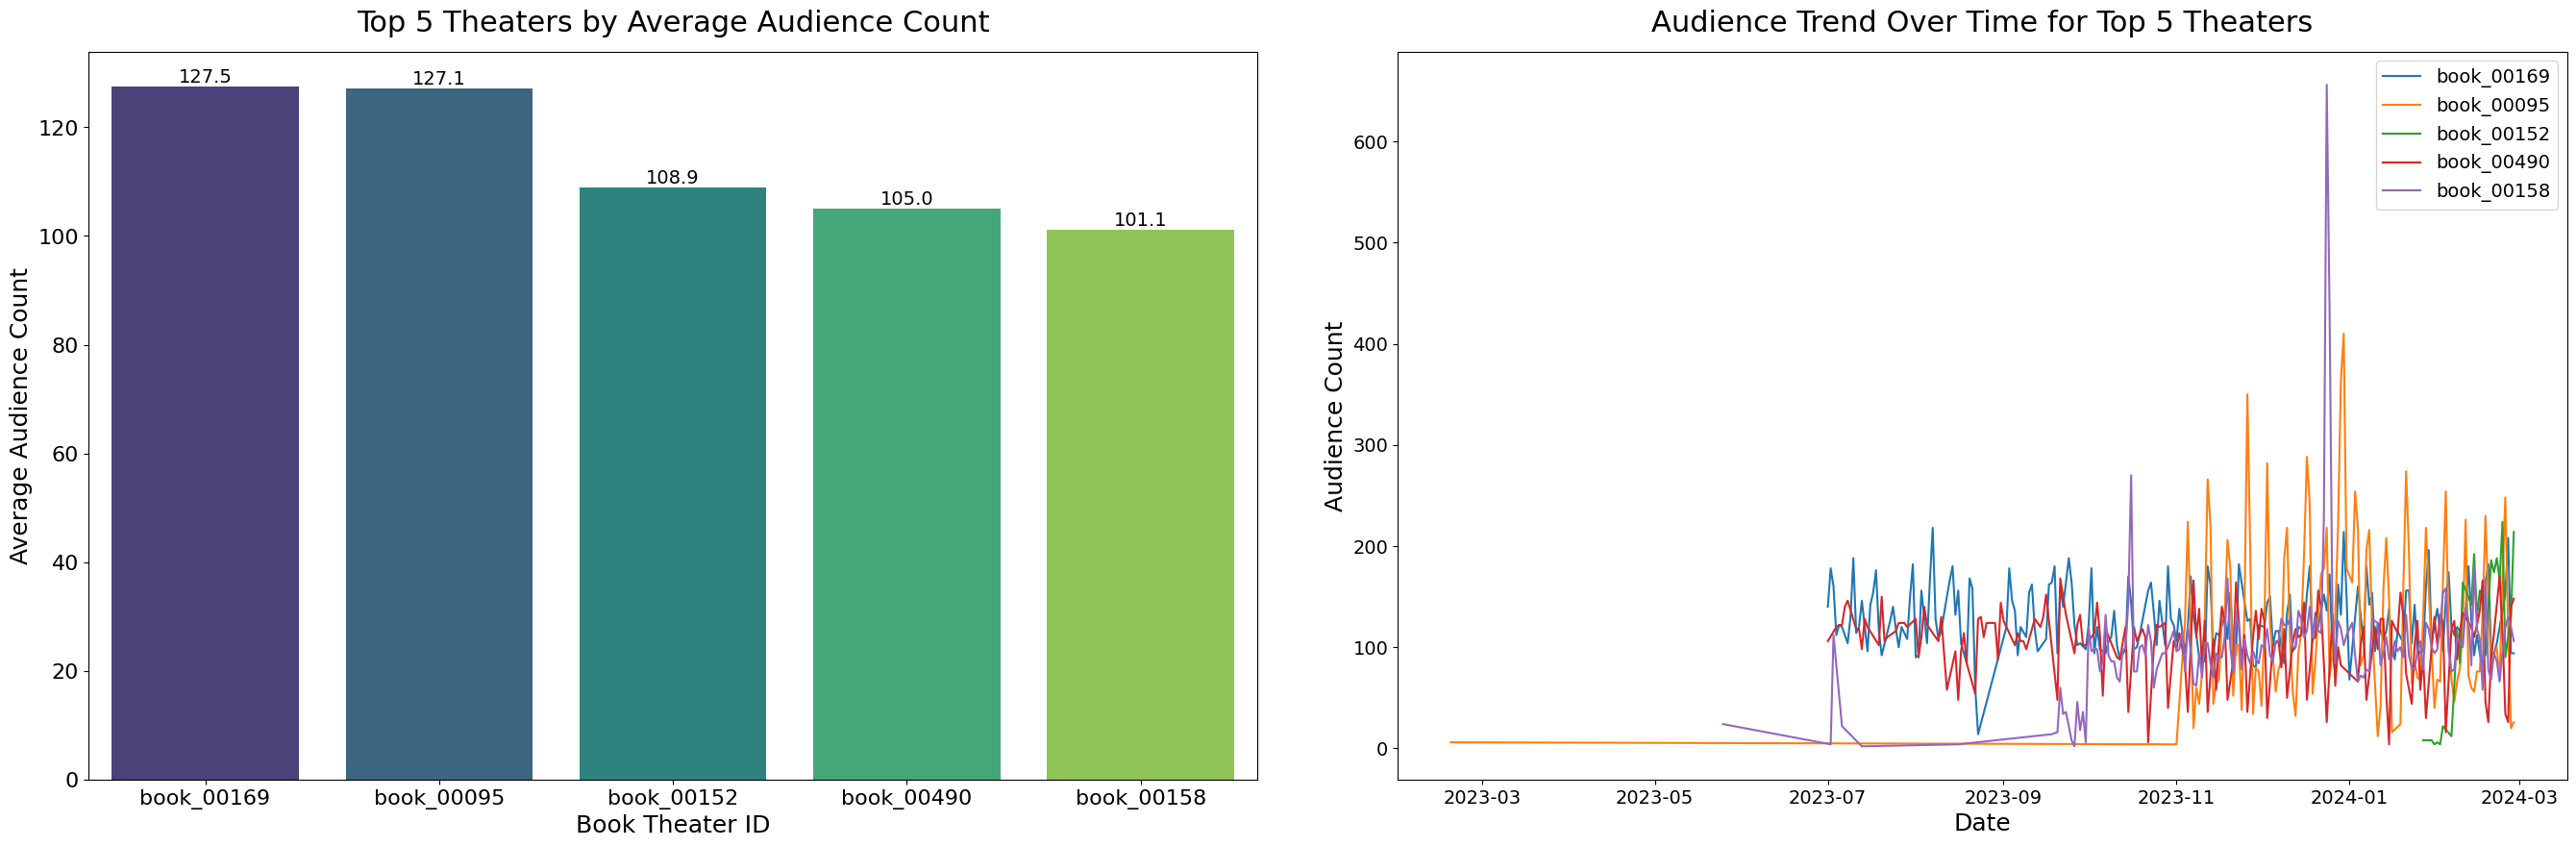

In [79]:
# Compute the average audience count for each theater and select the top 5
theater_avg = (dataset.groupby("book_theater_id")["audience_count"].mean()
               .sort_values(ascending=False).head(5))

top5 = theater_avg.head(5).index   # Theater IDs of the top 5 performers

# Create a figure with 2 subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(28, 10))

# Top 5 theater averages as bar plot
sns.barplot(x=theater_avg.index, y=theater_avg.values, ax=axes[0], palette="viridis")

axes[0].set_title("Top 5 Theaters by Average Audience Count", fontsize=22, pad=15)
axes[0].tick_params(axis='x', labelsize=16)
axes[0].tick_params(axis='y', labelsize=16)
axes[0].set_xlabel("Book Theater ID", fontsize=18)
axes[0].set_ylabel("Average Audience Count", fontsize=18)

# Add count labels on top of bars
for i, v in enumerate(theater_avg.head(5).values):
    axes[0].text(i, v, f"{v:.1f}", ha='center', va='bottom', fontsize=14)

# Time series audience trend for top 5 theaters
for t in top5:
    sub = dataset[dataset["book_theater_id"] == t]  # Filter rows for this theater
    axes[1].plot(sub["show_date"], sub["audience_count"], label=t)

axes[1].set_title("Audience Trend Over Time for Top 5 Theaters", fontsize=22, pad=15)
axes[1].legend(fontsize=14)
axes[1].tick_params(axis='x', labelsize=14)
axes[1].tick_params(axis='y', labelsize=14)
axes[1].set_xlabel("Date", fontsize=18)
axes[1].set_ylabel("Audience Count", fontsize=18)

# Adjust spacing between subplots
plt.tight_layout(pad=5)
plt.show()

## Correlation Heatmap of Numerical Features

#### Numerical features correlation heatmap

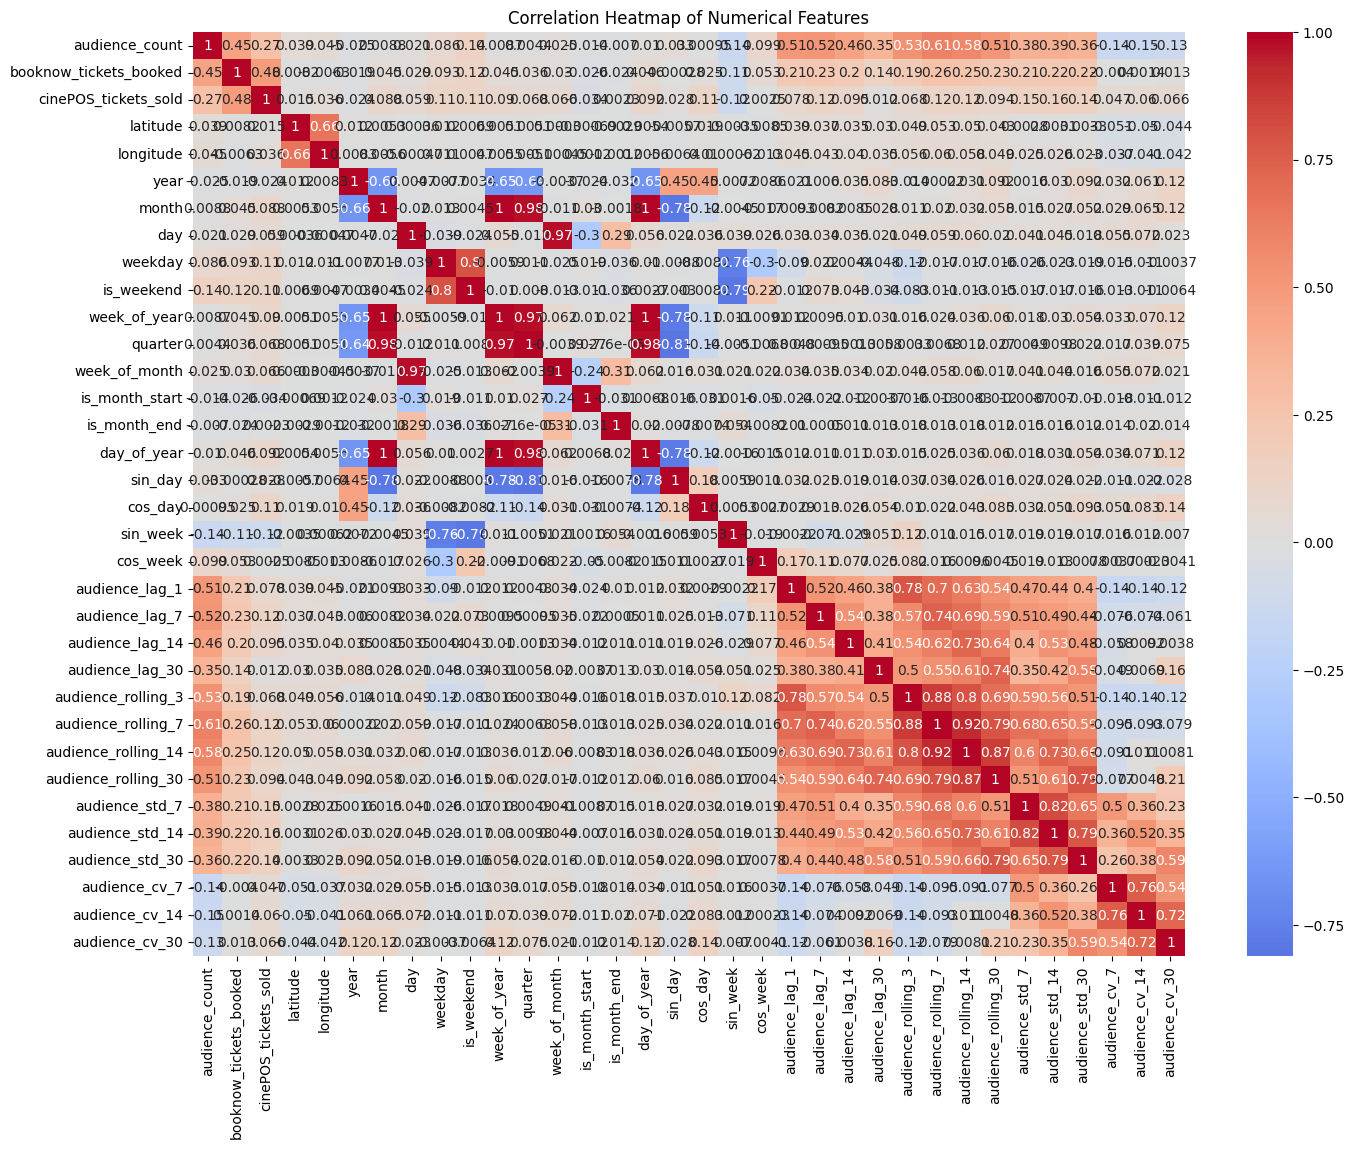

In [80]:
# Select numerical columns for correlation analysis
num = ['audience_count', 'booknow_tickets_booked', 'cinePOS_tickets_sold', 'latitude', 'longitude', 
       'year', 'month', 'day', 'weekday', 'is_weekend', 'week_of_year', 'quarter', 'week_of_month', 
       'is_month_start', 'is_month_end', 'day_of_year', 'sin_day', 'cos_day', 'sin_week', 'cos_week', 
       'audience_lag_1', 'audience_lag_7', 'audience_lag_14', 'audience_lag_30', 'audience_rolling_3', 
       'audience_rolling_7', 'audience_rolling_14', 'audience_rolling_30', 'audience_std_7', 
       'audience_std_14', 'audience_std_30', 'audience_cv_7', 'audience_cv_14', 'audience_cv_30']

# Create figure for the heatmap
plt.figure(figsize=(16,12))

# Compute correlation matrix for the selected numerical columns
corr = dataset[num].corr()

# Plot heatmap with annotations
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True)

# Set title
plt.title("Correlation Heatmap of Numerical Features")

# Display plot
plt.show()

## Audience Count Trend over Time

#### Time series plot of audience count

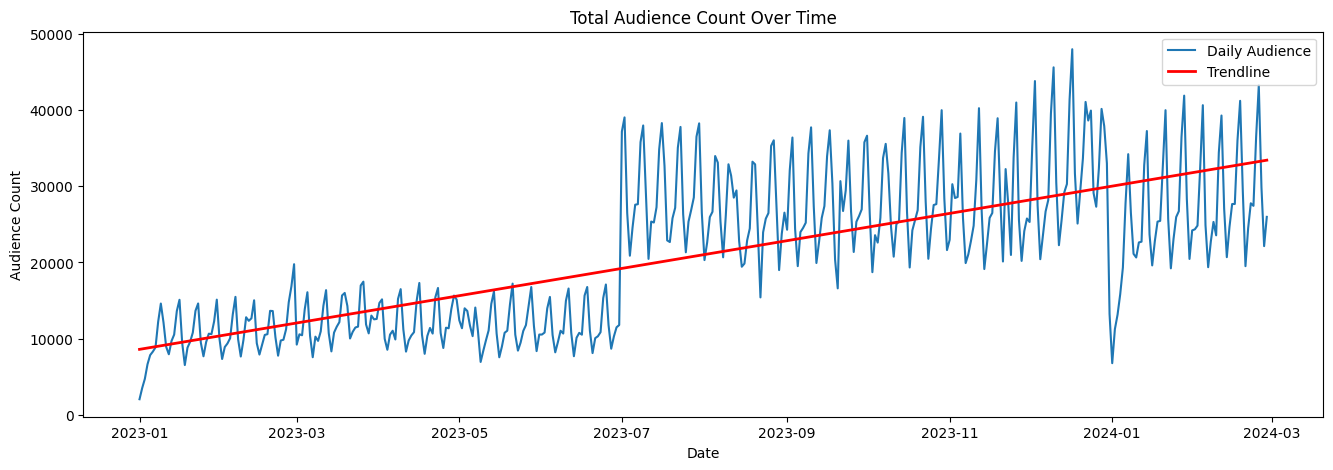

In [81]:
# Aggregate total audience count per day
audience_count_per_day = dataset.groupby("show_date")["audience_count"].sum().reset_index()

# Create an integer index for polynomial fitting
x = np.arange(len(audience_count_per_day))
# Extract audience totals as a NumPy array
y = audience_count_per_day["audience_count"].values

# Fit a 1st-degree polynomial (linear trend)
coeffs = np.polyfit(x, y, deg=1)
# Evaluate the fitted polynomial to get the trend line values
trend = np.polyval(coeffs, x)

# Plot daily audience counts and the trend line
plt.figure(figsize=(16,5))

# Time series plot of daily total audience
plt.plot(audience_count_per_day["show_date"], audience_count_per_day["audience_count"], label="Daily Audience")

# Plot linear trend line
plt.plot(audience_count_per_day["show_date"], trend, color="red", linewidth=2, label="Trendline")

# Titles and labels
plt.title("Total Audience Count Over Time")
plt.xlabel("Date")
plt.ylabel("Audience Count")
plt.legend()

# Display plot
plt.show()

## Geographical Distribution of Theaters

#### Geographical scatterplot of theaters marked by average performance

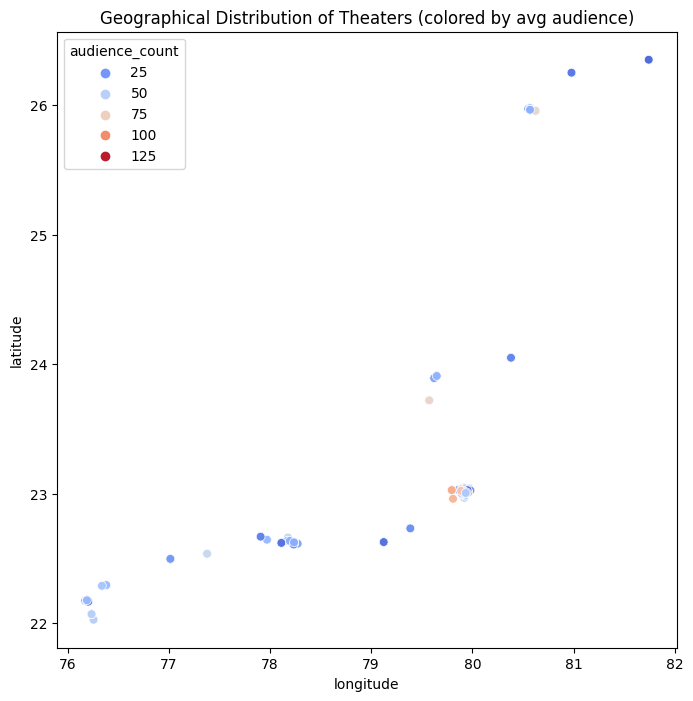

In [82]:
# Aggregate geographic and audience information at the theater level
geo = dataset.groupby("book_theater_id").agg({
    "latitude": "mean",          # Average latitude for each theater
    "longitude": "mean",         # Average longitude for each theater
    "audience_count": "mean"     # Average audience count per theater
}).reset_index()

# Create scatter plot showing theater positions on a map-like plane
plt.figure(figsize=(8,8))

sns.scatterplot(
    data=geo,
    x="longitude",               # X-axis = longitude (horizontal direction)
    y="latitude",                # Y-axis = latitude (vertical direction)
    hue="audience_count",        # Color intensity based on average audience
    palette="coolwarm",          # Blue → low audience, Red → high audience
    s=40                         # Marker size
)

# Set title
plt.title("Geographical Distribution of Theaters (colored by avg audience)")

# Display plot
plt.show()

#### **Key Findings and Insights based on the Dataset**

**1. Overall Audience Trend and Characteristics** -
**The total audience count exhibits a strong, increasing trend over the observation period, alongside pronounced short-term seasonality.**
* **Positive Growth Trend:** Total Audience Count over time clearly shows a positive linear trend in daily audience numbers from January 2023 through February 2024, as indicated by the upward-sloping red trendline.
* **Significant Volume Shift:** A major shift in audience volume occurred around July 2023. Before this point, daily audience peaks generally stayed below 20,000, while afterwards, peaks regularly exceeded 40,000 and sometimes approached 50,000.
* **Strong Seasonality/Volatility:** The daily audience count displays significant fluctuations (peaks and troughs) throughout the entire period, suggesting strong daily or weekly seasonality.
* **Audience Distribution:** The distribution of Audience Count shows that the audience count data is highly right-skewed. The vast majority of observations feature very low audience counts (clustering near 0), with fewer instances of very high counts (up to approximately 1400).
* **Yearly Increase:** The average audience count in 2024 appears higher than the average audience count in 2023, supporting the overall positive trend observed.

**2. Feature Impact and Seasonality** -
**Analysis of discrete features reveals specific drivers for audience numbers, with time-based features showing significant variation.**
* **Theater Type Dominance:** When grouped by theater_type, "Action" types have the highest average audience count.
* **Weekend Effect:** The variable is_weekend shows a clear impact, with days identified as weekends having a higher average audience count than non-weekend days.
* **Monthly Fluctuation:** The average audience count varies significantly by month, with December, March, and April leading.
* **Weekly Fluctuation:** The average audience count varies significantly by day of week, with Monday, Sunday, and Saturday leading.

**3. Correlation Insights**
* **Strong Time Series Dependence:** The audience count is highly dependent on its own recent past values, making it a time series task where historical data is crucial for prediction.

**4. Theater Performance and Geographical Distribution**
* **Top Performing Theaters:** The top 5 theaters by average audience count range from 101.1 to 127.5.
* **Top Theater Volatility:** The audience trend over time for the top 5 theaters shows they are highly volatile, exhibiting extreme spikes in audience count. One theater, represented by the purple line (book_00158), had a massive spike exceeding 600 audience members near the beginning of 2024, far above its average performance. Another theater, book_00095, represented by orange line stays between its usual range but shows high volatility.
* **Geographical Concentration of High Performers:** The geographical distribution plot indicates that theaters are concentrated in a roughly linear pattern. The theaters with the highest average audience counts (100 to 125, shown in red/dark red) appear to be concentrated in the central-mid area of the displayed map (around longitude 79 to 80 and latitude 23 to 24).

# Train/Validation Split

In [83]:
# Time-based split: Jan 2023 - Dec 2023 for training and Jan 2024 - Feb 2024 for validation
dataset = dataset.sort_values(['book_theater_id', 'show_date']).reset_index(drop=True)

# Split based on temporal cutoff
train = dataset[dataset['show_date'] < '2024-01-01']
val = dataset[dataset['show_date'] >= '2024-01-01']

print(f"Training set: {train.shape[0]} samples")
print(f"Validation set: {val.shape[0]} samples")

Training set: 174535 samples
Validation set: 39511 samples


# Dataset Pre-Processing

In [84]:
'''
# Date features
train = train.sort_values(['book_theater_id', 'show_date']).reset_index(drop=True)
train['year'] = train['show_date'].dt.year
train['month'] = train['show_date'].dt.month
train['day'] = train['show_date'].dt.day
train['weekday'] = train['show_date'].dt.weekday
train['is_weekend'] = train['weekday'].isin([5,6]).astype(int)
train['week_of_year'] = train['show_date'].dt.isocalendar().week.astype(int)
train['quarter'] = train['show_date'].dt.quarter
train['week_of_month'] = train['show_date'].apply(lambda d: (d.day-1)//7 + 1)
train['is_month_start'] = train['show_date'].dt.is_month_start.astype(int)
train['is_month_end'] = train['show_date'].dt.is_month_end.astype(int)
train['day_of_year'] = train['show_date'].dt.dayofyear
train['sin_day']  = np.sin(2 * np.pi * train['day_of_year'] / 365)
train['cos_day']  = np.cos(2 * np.pi * train['day_of_year'] / 365)
train['sin_week'] = np.sin(2 * np.pi * train['weekday'] / 7)
train['cos_week'] = np.cos(2 * np.pi * train['weekday'] / 7)

val = val.sort_values(['book_theater_id', 'show_date']).reset_index(drop=True)
val['year'] = val['show_date'].dt.year
val['month'] = val['show_date'].dt.month
val['day'] = val['show_date'].dt.day
val['weekday'] = val['show_date'].dt.weekday
val['is_weekend'] = val['weekday'].isin([5,6]).astype(int)
val['week_of_year'] = val['show_date'].dt.isocalendar().week.astype(int)
val['quarter'] = val['show_date'].dt.quarter
val['week_of_month'] = val['show_date'].apply(lambda d: (d.day-1)//7 + 1)
val['is_month_start'] = val['show_date'].dt.is_month_start.astype(int)
val['is_month_end'] = val['show_date'].dt.is_month_end.astype(int)
val['day_of_year'] = val['show_date'].dt.dayofyear
val['sin_day']  = np.sin(2 * np.pi * val['day_of_year'] / 365)
val['cos_day']  = np.cos(2 * np.pi * val['day_of_year'] / 365)
val['sin_week'] = np.sin(2 * np.pi * val['weekday'] / 7)
val['cos_week'] = np.cos(2 * np.pi * val['weekday'] / 7)
'''

"\n# Date features\ntrain = train.sort_values(['book_theater_id', 'show_date']).reset_index(drop=True)\ntrain['year'] = train['show_date'].dt.year\ntrain['month'] = train['show_date'].dt.month\ntrain['day'] = train['show_date'].dt.day\ntrain['weekday'] = train['show_date'].dt.weekday\ntrain['is_weekend'] = train['weekday'].isin([5,6]).astype(int)\ntrain['week_of_year'] = train['show_date'].dt.isocalendar().week.astype(int)\ntrain['quarter'] = train['show_date'].dt.quarter\ntrain['week_of_month'] = train['show_date'].apply(lambda d: (d.day-1)//7 + 1)\ntrain['is_month_start'] = train['show_date'].dt.is_month_start.astype(int)\ntrain['is_month_end'] = train['show_date'].dt.is_month_end.astype(int)\ntrain['day_of_year'] = train['show_date'].dt.dayofyear\ntrain['sin_day']  = np.sin(2 * np.pi * train['day_of_year'] / 365)\ntrain['cos_day']  = np.cos(2 * np.pi * train['day_of_year'] / 365)\ntrain['sin_week'] = np.sin(2 * np.pi * train['weekday'] / 7)\ntrain['cos_week'] = np.cos(2 * np.pi * tr

In [85]:
'''
# Lag features
train = train.sort_values(['book_theater_id', 'show_date']).reset_index(drop=True)
train['audience_lag_1'] = train.groupby('book_theater_id')['audience_count'].shift(1).fillna(0)
train['audience_lag_7'] = train.groupby('book_theater_id')['audience_count'].shift(7).fillna(0)
train['audience_lag_14'] = train.groupby('book_theater_id')['audience_count'].shift(14).fillna(0)
train['audience_lag_30'] = train.groupby('book_theater_id')['audience_count'].shift(30).fillna(0)

val = val.sort_values(['book_theater_id', 'show_date']).reset_index(drop=True)
val['audience_lag_1'] = val.groupby('book_theater_id')['audience_count'].shift(1).fillna(0)
val['audience_lag_7'] = val.groupby('book_theater_id')['audience_count'].shift(7).fillna(0)
val['audience_lag_14'] = val.groupby('book_theater_id')['audience_count'].shift(14).fillna(0)
val['audience_lag_30'] = val.groupby('book_theater_id')['audience_count'].shift(30).fillna(0)
'''

"\n# Lag features\ntrain = train.sort_values(['book_theater_id', 'show_date']).reset_index(drop=True)\ntrain['audience_lag_1'] = train.groupby('book_theater_id')['audience_count'].shift(1).fillna(0)\ntrain['audience_lag_7'] = train.groupby('book_theater_id')['audience_count'].shift(7).fillna(0)\ntrain['audience_lag_14'] = train.groupby('book_theater_id')['audience_count'].shift(14).fillna(0)\ntrain['audience_lag_30'] = train.groupby('book_theater_id')['audience_count'].shift(30).fillna(0)\n\nval = val.sort_values(['book_theater_id', 'show_date']).reset_index(drop=True)\nval['audience_lag_1'] = val.groupby('book_theater_id')['audience_count'].shift(1).fillna(0)\nval['audience_lag_7'] = val.groupby('book_theater_id')['audience_count'].shift(7).fillna(0)\nval['audience_lag_14'] = val.groupby('book_theater_id')['audience_count'].shift(14).fillna(0)\nval['audience_lag_30'] = val.groupby('book_theater_id')['audience_count'].shift(30).fillna(0)\n"

In [86]:
'''
# Rolling Averages
train = train.sort_values(['book_theater_id', 'show_date']).reset_index(drop=True)
train['audience_rolling_3'] = train.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(3).mean().fillna(0))
train['audience_rolling_7'] = train.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(7).mean().fillna(0))
train['audience_rolling_14'] = train.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(14).mean().fillna(0))
train['audience_rolling_30'] = train.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(30).mean().fillna(0))

val = val.sort_values(['book_theater_id', 'show_date']).reset_index(drop=True)
val['audience_rolling_3'] = val.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(3).mean().fillna(0))
val['audience_rolling_7'] = val.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(7).mean().fillna(0))
val['audience_rolling_14'] = val.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(14).mean().fillna(0))
val['audience_rolling_30'] = val.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(30).mean().fillna(0))
'''

"\n# Rolling Averages\ntrain = train.sort_values(['book_theater_id', 'show_date']).reset_index(drop=True)\ntrain['audience_rolling_3'] = train.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(3).mean().fillna(0))\ntrain['audience_rolling_7'] = train.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(7).mean().fillna(0))\ntrain['audience_rolling_14'] = train.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(14).mean().fillna(0))\ntrain['audience_rolling_30'] = train.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(30).mean().fillna(0))\n\nval = val.sort_values(['book_theater_id', 'show_date']).reset_index(drop=True)\nval['audience_rolling_3'] = val.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(3).mean().fillna(0))\nval['audience_rolling_7'] = val.groupby('book_theater_id')['audience_count'].transform(lambda x: x.sh

In [87]:
'''
# Variability
train = train.sort_values(['book_theater_id', 'show_date']).reset_index(drop=True)
train['audience_std_7'] = train.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(7).std().fillna(0))
train['audience_std_14'] = train.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(14).std().fillna(0))
train['audience_std_30'] = train.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(30).std().fillna(0))
train['audience_cv_7'] = train['audience_std_7'] / (train['audience_rolling_7'] + 1)
train['audience_cv_14'] = train['audience_std_14'] / (train['audience_rolling_14'] + 1)
train['audience_cv_30'] = train['audience_std_30'] / (train['audience_rolling_30'] + 1)

val = val.sort_values(['book_theater_id', 'show_date']).reset_index(drop=True)
val['audience_std_7'] = val.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(7).std().fillna(0))
val['audience_std_14'] = val.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(14).std().fillna(0))
val['audience_std_30'] = val.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(30).std().fillna(0))
val['audience_cv_7'] = val['audience_std_7'] / (val['audience_rolling_7'] + 1)
val['audience_cv_14'] = val['audience_std_14'] / (val['audience_rolling_14'] + 1)
val['audience_cv_30'] = val['audience_std_30'] / (val['audience_rolling_30'] + 1)
'''

"\n# Variability\ntrain = train.sort_values(['book_theater_id', 'show_date']).reset_index(drop=True)\ntrain['audience_std_7'] = train.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(7).std().fillna(0))\ntrain['audience_std_14'] = train.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(14).std().fillna(0))\ntrain['audience_std_30'] = train.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(30).std().fillna(0))\ntrain['audience_cv_7'] = train['audience_std_7'] / (train['audience_rolling_7'] + 1)\ntrain['audience_cv_14'] = train['audience_std_14'] / (train['audience_rolling_14'] + 1)\ntrain['audience_cv_30'] = train['audience_std_30'] / (train['audience_rolling_30'] + 1)\n\nval = val.sort_values(['book_theater_id', 'show_date']).reset_index(drop=True)\nval['audience_std_7'] = val.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(7).std().fillna(0))\nval[

## Handle Missing Values

### Fill missing values using theater metadata and imputation strategies

In [88]:
dataset.isna().sum()

book_theater_id                0
show_date                      0
audience_count                 0
booknow_tickets_booked    193005
cinePOS_tickets_sold      202896
theater_type              133896
theater_area              133896
latitude                  133896
longitude                 133896
day_of_week                    0
year                           0
month                          0
day                            0
weekday                        0
is_weekend                     0
week_of_year                   0
quarter                        0
week_of_month                  0
is_month_start                 0
is_month_end                   0
day_of_year                    0
sin_day                        0
cos_day                        0
sin_week                       0
cos_week                       0
audience_lag_1                 0
audience_lag_7                 0
audience_lag_14                0
audience_lag_30                0
audience_rolling_3             0
audience_r

In [89]:
train.isna().sum()

book_theater_id                0
show_date                      0
audience_count                 0
booknow_tickets_booked    160506
cinePOS_tickets_sold      165634
theater_type              109623
theater_area              109623
latitude                  109623
longitude                 109623
day_of_week                    0
year                           0
month                          0
day                            0
weekday                        0
is_weekend                     0
week_of_year                   0
quarter                        0
week_of_month                  0
is_month_start                 0
is_month_end                   0
day_of_year                    0
sin_day                        0
cos_day                        0
sin_week                       0
cos_week                       0
audience_lag_1                 0
audience_lag_7                 0
audience_lag_14                0
audience_lag_30                0
audience_rolling_3             0
audience_r

In [90]:
val.isna().sum()

book_theater_id               0
show_date                     0
audience_count                0
booknow_tickets_booked    32499
cinePOS_tickets_sold      37262
theater_type              24273
theater_area              24273
latitude                  24273
longitude                 24273
day_of_week                   0
year                          0
month                         0
day                           0
weekday                       0
is_weekend                    0
week_of_year                  0
quarter                       0
week_of_month                 0
is_month_start                0
is_month_end                  0
day_of_year                   0
sin_day                       0
cos_day                       0
sin_week                      0
cos_week                      0
audience_lag_1                0
audience_lag_7                0
audience_lag_14               0
audience_lag_30               0
audience_rolling_3            0
audience_rolling_7            0
audience

In [91]:
# Create mapping of CinePOS theater metadata to BookNow IDs
cinePOS_map = movie_theater_id_relation.merge(
    cinePOS_theaters,
    on='cine_theater_id',
    how='left'
).drop_duplicates('book_theater_id')

In [92]:
cinePOS_map.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   book_theater_id  150 non-null    object 
 1   cine_theater_id  150 non-null    object 
 2   theater_type     63 non-null     object 
 3   theater_area     63 non-null     object 
 4   latitude         11 non-null     float64
 5   longitude        11 non-null     float64
dtypes: float64(2), object(4)
memory usage: 7.2+ KB


In [93]:
# Merge CinePOS metadata into dataset (with suffixes)
dataset = dataset.merge(
    cinePOS_map[['book_theater_id', 'theater_type', 'theater_area', 'latitude', 'longitude']],
    on='book_theater_id', how='left', suffixes=('', '_cine'))

In [94]:
# Fill missing values with metadata where available
dataset['theater_type'] = dataset['theater_type'].combine_first(dataset['theater_type_cine'])
dataset['theater_area'] = dataset['theater_area'].combine_first(dataset['theater_area_cine'])
dataset['latitude'] = dataset['latitude'].combine_first(dataset['latitude_cine'])
dataset['longitude'] = dataset['longitude'].combine_first(dataset['longitude_cine'])

In [95]:
# Drop temporary CinePOS columns
dataset.drop(columns=[
    'theater_type_cine', 'theater_area_cine',
    'latitude_cine', 'longitude_cine'
], inplace=True)

In [96]:
# Repeat for train and validation datasets
train = train.merge(
    cinePOS_map[['book_theater_id', 'theater_type', 'theater_area', 'latitude', 'longitude']],
    on='book_theater_id', how='left', suffixes=('', '_cine'))

val = val.merge(
    cinePOS_map[['book_theater_id', 'theater_type', 'theater_area', 'latitude', 'longitude']],
    on='book_theater_id', how='left', suffixes=('', '_cine'))

train['theater_type'] = train['theater_type'].combine_first(train['theater_type_cine'])
train['theater_area'] = train['theater_area'].combine_first(train['theater_area_cine'])
train['latitude'] = train['latitude'].combine_first(train['latitude_cine'])
train['longitude'] = train['longitude'].combine_first(train['longitude_cine'])

val['theater_type'] = val['theater_type'].combine_first(val['theater_type_cine'])
val['theater_area'] = val['theater_area'].combine_first(val['theater_area_cine'])
val['latitude'] = val['latitude'].combine_first(val['latitude_cine'])
val['longitude'] = val['longitude'].combine_first(val['longitude_cine'])

train.drop(columns=[
    'theater_type_cine', 'theater_area_cine',
    'latitude_cine', 'longitude_cine'
], inplace=True)

val.drop(columns=[
    'theater_type_cine', 'theater_area_cine',
    'latitude_cine', 'longitude_cine'
], inplace=True)

In [97]:
# Fill booking counts with zero (missing = no bookings)
dataset['booknow_tickets_booked'] = dataset['booknow_tickets_booked'].fillna(0)
dataset['cinePOS_tickets_sold'] = dataset['cinePOS_tickets_sold'].fillna(0)

In [98]:
# Fill categorical features with mode per theater
dataset['theater_type'] = dataset.groupby('book_theater_id')['theater_type'] \
                                 .transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else np.nan))

dataset['theater_area'] = dataset.groupby('book_theater_id')['theater_area'] \
                                 .transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else np.nan))

In [99]:
# Fill numeric features with median per theater
dataset['latitude'] = dataset.groupby('book_theater_id')['latitude'] \
                             .transform(lambda x: x.fillna(x.median()))

dataset['longitude'] = dataset.groupby('book_theater_id')['longitude'] \
                              .transform(lambda x: x.fillna(x.median()))

In [100]:
# Repeat for train dataset
train['booknow_tickets_booked'] = train['booknow_tickets_booked'].fillna(0)
train['cinePOS_tickets_sold'] = train['cinePOS_tickets_sold'].fillna(0)

train['theater_type'] = train.groupby('book_theater_id')['theater_type'] \
                                 .transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else np.nan))

train['theater_area'] = train.groupby('book_theater_id')['theater_area'] \
                                 .transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else np.nan))

train['latitude'] = train.groupby('book_theater_id')['latitude'] \
                             .transform(lambda x: x.fillna(x.median()))

train['longitude'] = train.groupby('book_theater_id')['longitude'] \
                              .transform(lambda x: x.fillna(x.median()))

In [101]:
# Repeat for validation dataset
val['booknow_tickets_booked'] = val['booknow_tickets_booked'].fillna(0)
val['cinePOS_tickets_sold'] = val['cinePOS_tickets_sold'].fillna(0)

val['theater_type'] = val.groupby('book_theater_id')['theater_type'] \
                                 .transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else np.nan))

val['theater_area'] = val.groupby('book_theater_id')['theater_area'] \
                                 .transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else np.nan))

val['latitude'] = val.groupby('book_theater_id')['latitude'] \
                             .transform(lambda x: x.fillna(x.median()))

val['longitude'] = val.groupby('book_theater_id')['longitude'] \
                              .transform(lambda x: x.fillna(x.median()))

In [102]:
# SimpleImputer using global mode and median for remaining missing values
num_cols = ['latitude', 'longitude']
cat_cols = ['theater_type', 'theater_area']

num_imputer_dataset = SimpleImputer(strategy='median')
cat_imputer_dataset = SimpleImputer(strategy='most_frequent')

num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

dataset[num_cols] = num_imputer_dataset.fit_transform(dataset[num_cols])
dataset[cat_cols] = cat_imputer_dataset.fit_transform(dataset[cat_cols])

train[num_cols] = num_imputer.fit_transform(train[num_cols])
train[cat_cols] = cat_imputer.fit_transform(train[cat_cols])

val[num_cols] = num_imputer.transform(val[num_cols])
val[cat_cols] = cat_imputer.transform(val[cat_cols])

In [103]:
'''
dataset['theater_type'] = dataset['theater_type'].fillna('Unknown')
dataset['theater_area'] = dataset['theater_area'].fillna('Unknown')
dataset['latitude'] = dataset['latitude'].fillna(0)
dataset['longitude'] = dataset['longitude'].fillna(0)
'''

"\ndataset['theater_type'] = dataset['theater_type'].fillna('Unknown')\ndataset['theater_area'] = dataset['theater_area'].fillna('Unknown')\ndataset['latitude'] = dataset['latitude'].fillna(0)\ndataset['longitude'] = dataset['longitude'].fillna(0)\n"

In [104]:
# Checking for missing value after imputation
dataset_nulls = dataset.isnull().sum().sum()
train_nulls = train.isnull().sum().sum()
val_nulls = val.isnull().sum().sum()

dataset_nulls, train_nulls, val_nulls

(0, 0, 0)

## Feature Encoding and Scaling

### Encoding Categorical Features

In [105]:
# Checking categorical columns
cols = dataset.select_dtypes(include="object").columns
cols

Index(['book_theater_id', 'theater_type', 'theater_area', 'day_of_week'], dtype='object')

In [106]:
# Checking unique category count
book_theater_id_unique = dataset["book_theater_id"].nunique()
theater_type_unique = dataset["theater_type"].nunique()
theater_area_unique = dataset["theater_area"].nunique()

book_theater_id_unique, theater_type_unique, theater_area_unique

(826, 4, 86)

In [107]:
'''
# Target Encoding for High Cardinality
# book_theater_id_enc = mean audience per theater

target_map_theater_id_dataset = dataset.groupby('book_theater_id')['audience_count'].mean().to_dict()
dataset['book_theater_id_enc'] = dataset['book_theater_id'].map(target_map_theater_id_dataset)

target_map_theater_id = train.groupby('book_theater_id')['audience_count'].mean().to_dict()
train['book_theater_id_enc'] = train['book_theater_id'].map(target_map_theater_id)

global_audience_count_train_mean = train['audience_count'].mean()
val['book_theater_id_enc'] = val['book_theater_id'].map(lambda x: target_map_theater_id.get(
    x, global_audience_count_train_mean))
'''

"\n# Target Encoding for High Cardinality\n# book_theater_id_enc = mean audience per theater\n\ntarget_map_theater_id_dataset = dataset.groupby('book_theater_id')['audience_count'].mean().to_dict()\ndataset['book_theater_id_enc'] = dataset['book_theater_id'].map(target_map_theater_id_dataset)\n\ntarget_map_theater_id = train.groupby('book_theater_id')['audience_count'].mean().to_dict()\ntrain['book_theater_id_enc'] = train['book_theater_id'].map(target_map_theater_id)\n\nglobal_audience_count_train_mean = train['audience_count'].mean()\nval['book_theater_id_enc'] = val['book_theater_id'].map(lambda x: target_map_theater_id.get(\n    x, global_audience_count_train_mean))\n"

In [108]:
'''
# Ordinal Encoding for theater_type
oe_theater_type_dataset = OrdinalEncoder()
dataset['theater_type_enc'] = oe_theater_type_dataset.fit_transform(dataset[['theater_type']])

oe_theater_type = OrdinalEncoder()
train['theater_type_enc'] = oe_theater_type.fit_transform(train[['theater_type']])
val['theater_type_enc'] = oe_theater_type.transform(val[['theater_type']])
'''

"\n# Ordinal Encoding for theater_type\noe_theater_type_dataset = OrdinalEncoder()\ndataset['theater_type_enc'] = oe_theater_type_dataset.fit_transform(dataset[['theater_type']])\n\noe_theater_type = OrdinalEncoder()\ntrain['theater_type_enc'] = oe_theater_type.fit_transform(train[['theater_type']])\nval['theater_type_enc'] = oe_theater_type.transform(val[['theater_type']])\n"

In [109]:
'''
# Ordinal Encoding for theater_area
oe_theater_area_dataset = OrdinalEncoder()
dataset['theater_area_enc'] = oe_theater_area_dataset.fit_transform(dataset[['theater_area']])

oe_theater_area = OrdinalEncoder()
train['theater_area_enc'] = oe_theater_area.fit_transform(train[['theater_area']])
val['theater_area_enc']   = oe_theater_area.transform(val[['theater_area']])
'''

"\n# Ordinal Encoding for theater_area\noe_theater_area_dataset = OrdinalEncoder()\ndataset['theater_area_enc'] = oe_theater_area_dataset.fit_transform(dataset[['theater_area']])\n\noe_theater_area = OrdinalEncoder()\ntrain['theater_area_enc'] = oe_theater_area.fit_transform(train[['theater_area']])\nval['theater_area_enc']   = oe_theater_area.transform(val[['theater_area']])\n"

In [110]:
# Define feature columns for modeling
feature_cols = ['book_theater_id', 'booknow_tickets_booked', 'cinePOS_tickets_sold', 'theater_type', 
                  'theater_area', 'latitude', 'longitude', 'year', 'month', 'day', 'weekday', 'is_weekend', 
                  'week_of_year', 'quarter', 'week_of_month', 'is_month_start', 'is_month_end', 'day_of_year', 
                  'sin_day', 'cos_day', 'sin_week', 'cos_week', 'audience_lag_1', 'audience_lag_7', 
                  'audience_lag_14', 'audience_lag_30', 'audience_rolling_3', 'audience_rolling_7', 
                  'audience_rolling_14', 'audience_rolling_30', 'audience_std_7', 'audience_std_14', 
                  'audience_std_30', 'audience_cv_7', 'audience_cv_14', 'audience_cv_30']

In [111]:
# Encode categorical variables using Target Encoding and Ordinal Encoding

# Categorize columns by encoding type
target_enc_col = ['book_theater_id'] # High cardinality: target encoding
ordinal_enc_cols = ['theater_type', 'theater_area'] # Low cardinality: ordinal encoding

# Remaining columns are kept as-is (already numeric)
numeric_cols = [col for col in feature_cols 
                if col not in target_enc_col 
                and col not in ordinal_enc_cols]

In [112]:
# Create encoding pipeline
transformer = ColumnTransformer(
    transformers=[
        ('target_enc', TargetEncoder(categories="auto", target_type="continuous", smooth="auto"), target_enc_col),
        ('ordinal_enc', OrdinalEncoder(), ordinal_enc_cols)
    ], remainder='passthrough',
    verbose_feature_names_out=False
)

pipeline = Pipeline([('encoder', transformer)])

# Keeping pipeline output as pandas dataframe for modeling
pipeline.set_output(transform="pandas")

# Prepare train/validation sets
X_train = train[feature_cols]
y_train = train['audience_count']
X_val = val[feature_cols]
y_val = val['audience_count']

# Apply encoding
X_train_processed = pipeline.fit_transform(X_train, y_train)
X_val_processed = pipeline.transform(X_val)

In [113]:
# Process full dataset for final model training
dataset_features = dataset[feature_cols]
dataset_target = dataset['audience_count']

transformer_dataset = ColumnTransformer(
    transformers=[
        ('target_enc', TargetEncoder(categories="auto", target_type="continuous", smooth="auto"), target_enc_col),
        ('ordinal_enc', OrdinalEncoder(), ordinal_enc_cols)
    ], remainder='passthrough',
    verbose_feature_names_out=False
)

pipeline_dataset = Pipeline([
    ('encoder', transformer_dataset)
])

pipeline_dataset.set_output(transform="pandas")

dataset_processed = pipeline_dataset.fit_transform(dataset_features, dataset_target)

### Scaling Numerical Features

#### Justification for Not Scaling Numerical Features

**I chose not to scale numerical features for the following reasons:**

* **Tree-based models do not benefit from scaling:**
  Models such as Decision Tree, Random Forest, Extra Trees, GradientBoosting, HistGradientBoosting, XGBoost, LightGBM are invariant to feature rescaling because they split on feature thresholds rather than Euclidean distances. Scaling therefore does not improve performance and sometimes adds unnecessary complexity.
* **Several features in the dataset are inherently structured and scaling would distort them:**
  Scaling these features would remove or distort the natural relationships, raw magnitudes, and distributions that the tree models can exploit effectively.
  1. Date-based features (year, month, day, etc.)
  2. Lag features (audience_lag_1, audience_lag_7, etc.)
  3. Rolling statistics (audience_rolling_7, audience_std_7, audience_cv_7, etc.)
  4. Cyclical encodings (sin/cos of day and week, already normalized to [-1, 1])
  5. Geospatial features (latitude and longitude), where scaling would destroy spatial relationships
  6. Target-encoded and ordinal-encoded categorical features, whose numeric magnitude carries meaningful information

In [114]:
dataset_processed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214046 entries, 0 to 214045
Data columns (total 36 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   book_theater_id         214046 non-null  float64
 1   theater_type            214046 non-null  float64
 2   theater_area            214046 non-null  float64
 3   booknow_tickets_booked  214046 non-null  float64
 4   cinePOS_tickets_sold    214046 non-null  float64
 5   latitude                214046 non-null  float64
 6   longitude               214046 non-null  float64
 7   year                    214046 non-null  int32  
 8   month                   214046 non-null  int32  
 9   day                     214046 non-null  int32  
 10  weekday                 214046 non-null  int32  
 11  is_weekend              214046 non-null  int64  
 12  week_of_year            214046 non-null  int64  
 13  quarter                 214046 non-null  int32  
 14  week_of_month       

In [115]:
X_train_processed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 174535 entries, 0 to 174534
Data columns (total 36 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   book_theater_id         174535 non-null  float64
 1   theater_type            174535 non-null  float64
 2   theater_area            174535 non-null  float64
 3   booknow_tickets_booked  174535 non-null  float64
 4   cinePOS_tickets_sold    174535 non-null  float64
 5   latitude                174535 non-null  float64
 6   longitude               174535 non-null  float64
 7   year                    174535 non-null  int32  
 8   month                   174535 non-null  int32  
 9   day                     174535 non-null  int32  
 10  weekday                 174535 non-null  int32  
 11  is_weekend              174535 non-null  int64  
 12  week_of_year            174535 non-null  int64  
 13  quarter                 174535 non-null  int32  
 14  week_of_month       

In [116]:
X_val_processed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39511 entries, 0 to 39510
Data columns (total 36 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   book_theater_id         39511 non-null  float64
 1   theater_type            39511 non-null  float64
 2   theater_area            39511 non-null  float64
 3   booknow_tickets_booked  39511 non-null  float64
 4   cinePOS_tickets_sold    39511 non-null  float64
 5   latitude                39511 non-null  float64
 6   longitude               39511 non-null  float64
 7   year                    39511 non-null  int32  
 8   month                   39511 non-null  int32  
 9   day                     39511 non-null  int32  
 10  weekday                 39511 non-null  int32  
 11  is_weekend              39511 non-null  int64  
 12  week_of_year            39511 non-null  int64  
 13  quarter                 39511 non-null  int32  
 14  week_of_month           39511 non-null

# Model Training and Evaluation

### **Train multiple models and compare performance**

In [117]:
# Assigns processed training/validation datasets and their corresponding targets into X_train, y_train, X_val, and y_val
X_train = X_train_processed
y_train = train['audience_count']
X_val = X_val_processed
y_val = val['audience_count']

In [118]:
# Define candidate models with reasonable default parameters as initial starting point
models = [
    ("DecisionTree", DecisionTreeRegressor(max_depth=8, random_state=42)),
    ("RandomForest", RandomForestRegressor(n_estimators=700, max_depth=12, min_samples_split=200, min_samples_leaf=30, max_features="sqrt", bootstrap=True,random_state=42, n_jobs=-1, verbose=0)),
    ("ExtraTrees", ExtraTreesRegressor(n_estimators=800, max_depth=None, random_state=42, n_jobs=-1, verbose=0)),
    ("GradientBoosting", GradientBoostingRegressor(n_estimators=800, learning_rate=0.01, max_depth=5, random_state=42, verbose=0)),
    ("HistGradientBoosting", HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_depth=None, random_state=42)),
    ("XGBoost", XGBRegressor(n_estimators=500, max_depth=8, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.2, reg_alpha=0.1, random_state=42, n_jobs=-1, verbosity=0)),
    ("LightGBM", LGBMRegressor(n_estimators=1000, learning_rate=0.05, num_leaves=31, max_depth=-1, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, reg_alpha=0.0, random_state=42, n_jobs=-1, verbose=-1))
]

results = []
trained_models = {}

# Train and evaluate each model
for name, model_choice in models:
    # Model Name
    print(f"\nTraining {name}...")
    
    # Model Pipeline
    model = Pipeline([('regressor', model_choice)])

    # Fit
    model.fit(X_train, y_train)
    # Predict
    y_pred = model.predict(X_val)
    # Evaluate
    score = r2_score(y_val, y_pred)

    # Store results
    results.append({
        'Model': name,
        'R2_Score': round(score, 4),
        'Parameters': model_choice.get_params()
    })

    # Store trained model
    trained_models[name] = model

    # Print model summary
    print("="*50)
    print(f"Model: {name}")
    print(f"R² Score: {score:.4f}")
    print("Parameters:")
    for k, v in model_choice.get_params().items():
        print(f"  {k}: {v}")
    print("="*50)

results_df = pd.DataFrame(results).sort_values(by='R2_Score', ascending=False)


Training DecisionTree...
Model: DecisionTree
R² Score: 0.4719
Parameters:
  ccp_alpha: 0.0
  criterion: squared_error
  max_depth: 8
  max_features: None
  max_leaf_nodes: None
  min_impurity_decrease: 0.0
  min_samples_leaf: 1
  min_samples_split: 2
  min_weight_fraction_leaf: 0.0
  monotonic_cst: None
  random_state: 42
  splitter: best

Training RandomForest...
Model: RandomForest
R² Score: 0.5297
Parameters:
  bootstrap: True
  ccp_alpha: 0.0
  criterion: squared_error
  max_depth: 12
  max_features: sqrt
  max_leaf_nodes: None
  max_samples: None
  min_impurity_decrease: 0.0
  min_samples_leaf: 30
  min_samples_split: 200
  min_weight_fraction_leaf: 0.0
  monotonic_cst: None
  n_estimators: 700
  n_jobs: -1
  oob_score: False
  random_state: 42
  verbose: 0
  warm_start: False

Training ExtraTrees...
Model: ExtraTrees
R² Score: 0.5215
Parameters:
  bootstrap: False
  ccp_alpha: 0.0
  criterion: squared_error
  max_depth: None
  max_features: 1.0
  max_leaf_nodes: None
  max_sampl

In [119]:
# Training Result
results_df

,Model,R2_Score,Parameters
6,LightGBM,0.5368,"{'boosting_type': 'gbdt', 'class_weight': None..."
4,HistGradientBoosting,0.5337,"{'categorical_features': 'from_dtype', 'early_..."
3,GradientBoosting,0.5330,"{'alpha': 0.9, 'ccp_alpha': 0.0, 'criterion': ..."
1,RandomForest,0.5297,"{'bootstrap': True, 'ccp_alpha': 0.0, 'criteri..."
2,ExtraTrees,0.5215,"{'bootstrap': False, 'ccp_alpha': 0.0, 'criter..."
5,XGBoost,0.5197,"{'objective': 'reg:squarederror', 'base_score'..."
0,DecisionTree,0.4719,"{'ccp_alpha': 0.0, 'criterion': 'squared_error..."


In [120]:
# Best Trained Model
best_model_name = results_df.loc[results_df['R2_Score'].idxmax(), 'Model']
best_model = trained_models[best_model_name]
best_r2 = results_df.loc[results_df['R2_Score'].idxmax(), 'R2_Score']

print(f"Best Model: {best_model_name} with R² = {best_r2:.4f}")

Best Model: LightGBM with R² = 0.5368


#### **Key Findings based on Model Performance**

* **Top Performer (Best R2 Score): LightGBM**  
The LightGBM Regressor achieved the highest R2 score on the validation set. It was configured with 1000 estimators, a learning rate of 0.05, and max_depth of -1 (meaning no limit).
* **Close Second: HistGradientBoosting**  
The HistGradientBoosting Regressor performed almost identically to LightGBM. It was configured with a maximum of 500 iterations (max_iter) and a learning rate of 0.05.
* **Middle Tier (Standard Ensembles and XGBoost):**    
    * RandomForest was the highest performer among the standard bagging/tree ensembles (700 estimators, max depth 12).
    * XGBoost, ExtraTrees and GradientBoosting followed.
* **Lowest Performer (Baseline Tree): DecisionTree**  
The single DecisionTree Regressor achieved the lowest R2 score. This model was constrained with max_depth=8.

#### **Key Insights based on Model Performance**
* **Ensemble Methods Superiority**  
A clear observation is that ensemble methods significantly outperformed the single DecisionTree Regressor. The performance gain from moving to an ensemble (like Random Forest) from the constrained single Decision Tree is significant.
* **Efficiency of Histogram-Based Boosting**  
The most insightful finding is the superior performance of the histogram-based gradient boosting models (LightGBM and HistGradientBoosting) compared to standard GradientBoosting (GB) and even XGBoost, using their initial parameter settings. LightGBM and HistGradientBoosting utilized similar learning rates (0.05). The difference in their results is minimal, suggesting both algorithms are highly effective for this dataset in their default configuration.
* **Parameter Impact and Configuration**  
XGBoost included specific L1 and L2 regularization terms (Lasso and Ridge) - reg_lambda=1.2, reg_alpha=0.1, while LightGBM used reg_lambda=1.0 and reg_alpha=0.0. Despite the slightly stronger regularization settings in XGBoost, it lagged behind the higher-performing histogram models.
* **Estimator Counts**  
LightGBM was initialized with the largest number of estimators (1000), while RandomForest and GradientBoosting and ExtraTrees used 800. The high R2 of LightGBM could potentially be attributed to its larger ensemble size, allowing for more fine-tuning steps during boosting, combined with its efficient algorithm structure.

# Hyperparameter Tuning

### **Fine-tune the best performing models using GridSearchCV**

In [121]:
'''# Define parameter grids for each model
param_grids = {
    "DecisionTree": {
        "max_depth": [5, 8, 12, None],
        "min_samples_split": [50, 100, 150, 200],
        "min_samples_leaf": [5, 15, 25, 45]
    },

    "RandomForest": {
        "n_estimators": [300, 500],
        "max_depth": [8, 10]
    },

    "ExtraTrees": {
        "n_estimators": [500, 800],
        "max_depth": [12, 20]
    },

    "GradientBoosting": {
        "n_estimators": [800, 1000],
        "learning_rate": [0.005, 0.01],
        "max_depth": [5, 7]
    },

    "HistGradientBoosting": {
        "max_depth": [12, 20],
        "learning_rate": [0.01, 0.05],
        "max_iter": [300, 500]
    },

    "XGBoost": {
        "n_estimators": [500],
        "max_depth": [7, 8, 9],
        "learning_rate": [0.01, 0.05],
        "subsample": [0.8],
        "colsample_bytree": [0.8],
        "reg_lambda": [1, 1.2],
        "reg_alpha": [0, 0.1]
    },

    "LightGBM": {
        "n_estimators": [1000],
        "learning_rate": [0.01, 0.05],
        "num_leaves": [31, 63, 127],
        "max_depth": [7, 8, 9],
        "subsample": [0.8],
        "colsample_bytree": [0.8],
        "reg_lambda": [0, 1],
        "reg_alpha": [0, 0.1]
    }
}

# Initialize base models
models = {
    "DecisionTree": (DecisionTreeRegressor(random_state=42)),
    "RandomForest": (RandomForestRegressor(random_state=42, n_jobs=-1, verbose=0)),
    "ExtraTrees": (ExtraTreesRegressor(random_state=42, n_jobs=-1, verbose=0)),
    "GradientBoosting": (GradientBoostingRegressor(random_state=42, verbose=0)),
    "HistGradientBoosting": (HistGradientBoostingRegressor(random_state=42)),
    "XGBoost": (XGBRegressor(random_state=42, n_jobs=-1, verbosity=0)),
    "LightGBM": (LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1))
}

tuned_results = []
tuned_models = {}

# Perform grid search for each model
for name, model in models.items():
    print(f"\nTuning {name}...")

    # TimeSeriesSplit for time series cross-validation
    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring="r2",
        cv=TimeSeriesSplit(n_splits=3),
        n_jobs=-1,
        verbose=1
    )

    grid.fit(X_train, y_train)

    # Evaluate best model
    tuned_model = grid.best_estimator_
    y_pred = tuned_model.predict(X_val)
    score = r2_score(y_val, y_pred)

    tuned_results.append({
        "Model": name,
        "R2_Score_Tuned": round(score, 4),
        "Parameters_Tuned": grid.best_params_
    })

    tuned_models[name] = tuned_model

    print("="*50)
    print(f"Model: {name}")
    print(f"R² Score (Tuned): {score:.4f}")
    print("Best Parameters:")
    for k, v in grid.best_params_.items():
        print(f"  {k}: {v}")
    print("="*50)

tuned_results_df = pd.DataFrame(tuned_results).sort_values(by="R2_Score_Tuned", ascending=False)'''

'# Define parameter grids for each model\nparam_grids = {\n    "DecisionTree": {\n        "max_depth": [5, 8, 12, None],\n        "min_samples_split": [50, 100, 150, 200],\n        "min_samples_leaf": [5, 15, 25, 45]\n    },\n\n    "RandomForest": {\n        "n_estimators": [300, 500],\n        "max_depth": [8, 10]\n    },\n\n    "ExtraTrees": {\n        "n_estimators": [500, 800],\n        "max_depth": [12, 20]\n    },\n\n    "GradientBoosting": {\n        "n_estimators": [800, 1000],\n        "learning_rate": [0.005, 0.01],\n        "max_depth": [5, 7]\n    },\n\n    "HistGradientBoosting": {\n        "max_depth": [12, 20],\n        "learning_rate": [0.01, 0.05],\n        "max_iter": [300, 500]\n    },\n\n    "XGBoost": {\n        "n_estimators": [500],\n        "max_depth": [7, 8, 9],\n        "learning_rate": [0.01, 0.05],\n        "subsample": [0.8],\n        "colsample_bytree": [0.8],\n        "reg_lambda": [1, 1.2],\n        "reg_alpha": [0, 0.1]\n    },\n\n    "LightGBM": {\n  

In [122]:
'''# Tuning Result
tuned_results_df'''

'# Tuning Result\ntuned_results_df'

In [123]:
'''# Best Tuned Model
best_tuned_model_name = tuned_results_df.loc[tuned_results_df['R2_Score_Tuned'].idxmax(), 'Model']
best_tuned_model = tuned_models[best_tuned_model_name]
best_tuned_r2 = tuned_results_df.loc[tuned_results_df['R2_Score_Tuned'].idxmax(), 'R2_Score_Tuned']

print(f"Best Tuned Model: {best_tuned_model_name} with R² = {best_tuned_r2:.4f}")'''

'# Best Tuned Model\nbest_tuned_model_name = tuned_results_df.loc[tuned_results_df[\'R2_Score_Tuned\'].idxmax(), \'Model\']\nbest_tuned_model = tuned_models[best_tuned_model_name]\nbest_tuned_r2 = tuned_results_df.loc[tuned_results_df[\'R2_Score_Tuned\'].idxmax(), \'R2_Score_Tuned\']\n\nprint(f"Best Tuned Model: {best_tuned_model_name} with R² = {best_tuned_r2:.4f}")'

# Model Comparison

In [124]:
'''# Merge baseline and tuned model results
comparison_df = results_df.merge(tuned_results_df, on='Model')

# Calculate % improvement in R² for each model
comparison_df['Change %'] = ((comparison_df['R2_Score_Tuned'] - comparison_df['R2_Score']) / comparison_df['R2_Score']) * 100

# Sort models by the highest performance gain after tuning
comparison_df = comparison_df.sort_values(by='Change %', ascending=False).reset_index(drop=True)'''

"# Merge baseline and tuned model results\ncomparison_df = results_df.merge(tuned_results_df, on='Model')\n\n# Calculate % improvement in R² for each model\ncomparison_df['Change %'] = ((comparison_df['R2_Score_Tuned'] - comparison_df['R2_Score']) / comparison_df['R2_Score']) * 100\n\n# Sort models by the highest performance gain after tuning\ncomparison_df = comparison_df.sort_values(by='Change %', ascending=False).reset_index(drop=True)"

In [125]:
'''# Comparison
print("\nComparison of R2 Score Before vs After Hyperparameter Tuning:\n")
comparison_df'''

'# Comparison\nprint("\nComparison of R2 Score Before vs After Hyperparameter Tuning:\n")\ncomparison_df'

In [126]:
'''# Visual Comparison
plt.figure(figsize=(10,6))
plt.bar(comparison_df['Model'], comparison_df['Change %'])
plt.ylabel('R2 Score Improvement (%)')
plt.title('Model Performance Improvement After Hyperparameter Tuning')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()'''

"# Visual Comparison\nplt.figure(figsize=(10,6))\nplt.bar(comparison_df['Model'], comparison_df['Change %'])\nplt.ylabel('R2 Score Improvement (%)')\nplt.title('Model Performance Improvement After Hyperparameter Tuning')\nplt.xticks(rotation=45)\nplt.tight_layout()\nplt.show()"

# Prediction

In [127]:
# Initialize best model (using best parameters found)
final_model = RandomForestRegressor(n_estimators=700, max_depth=12, min_samples_split=200, min_samples_leaf=30, max_features="sqrt", bootstrap=True,random_state=42, n_jobs=-1, verbose=0)

In [128]:
# Refit best model on whole dataset for final prediction

X_full = dataset_processed
y_full = dataset['audience_count']

final_model.fit(X_full, y_full)

print("Final model RandomForestRegressor refitted on full processed dataset.")

Final model RandomForestRegressor refitted on full processed dataset.


In [129]:
# Test set preparation for submission
test = sample_submission.copy()

# Parse ID to extract theater and date information
test['book_theater_id'] = test['ID'].apply(lambda x: x.split('_')[0] + "_" + x.split('_')[1])
test['show_date'] = pd.to_datetime(test['ID'].apply(lambda x: x.split('_')[2]))

In [130]:
# Merge theater metadata
test = test.merge(
    booknow_theaters[['book_theater_id', 'theater_type', 'theater_area', 'latitude', 'longitude']],
    on='book_theater_id', how='left'
)

# Initialize booking features (not available for test set)
test['booknow_tickets_booked'] = 0
test['cinePOS_tickets_sold'] = 0

In [131]:
# Combine train and test for lag feature generation
temp = pd.concat([dataset[['book_theater_id','show_date','audience_count']], 
                  test[['book_theater_id','show_date']].assign(audience_count=np.nan)])

temp = temp.sort_values(['book_theater_id','show_date'])

In [132]:
# Create time-based features for test
test['year'] = test['show_date'].dt.year
test['month'] = test['show_date'].dt.month
test['day'] = test['show_date'].dt.day
test['weekday'] = test['show_date'].dt.weekday
test['is_weekend'] = test['weekday'].isin([5,6]).astype(int)
test['week_of_year'] = test['show_date'].dt.isocalendar().week.astype(int)
test['quarter'] = test['show_date'].dt.quarter
test['week_of_month'] = test['show_date'].apply(lambda d: (d.day-1)//7 + 1)
test['is_month_start'] = test['show_date'].dt.is_month_start.astype(int)
test['is_month_end'] = test['show_date'].dt.is_month_end.astype(int)
test['day_of_year'] = test['show_date'].dt.dayofyear

test['sin_day']  = np.sin(2 * np.pi * test['day_of_year'] / 365)
test['cos_day']  = np.cos(2 * np.pi * test['day_of_year'] / 365)
test['sin_week'] = np.sin(2 * np.pi * test['weekday'] / 7)
test['cos_week'] = np.cos(2 * np.pi * test['weekday'] / 7)

In [133]:
# Calculate lag and rolling features using combined data
temp['audience_lag_1']  = temp.groupby('book_theater_id')['audience_count'].shift(1).fillna(0)
temp['audience_lag_7']  = temp.groupby('book_theater_id')['audience_count'].shift(7).fillna(0)
temp['audience_lag_14'] = temp.groupby('book_theater_id')['audience_count'].shift(14).fillna(0)
temp['audience_lag_30'] = temp.groupby('book_theater_id')['audience_count'].shift(30).fillna(0)

temp['audience_rolling_3']  = temp.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(3).mean().fillna(0))
temp['audience_rolling_7']  = temp.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(7).mean().fillna(0))
temp['audience_rolling_14'] = temp.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(14).mean().fillna(0))
temp['audience_rolling_30'] = temp.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(30).mean().fillna(0))

temp['audience_std_7']  = temp.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(7).std().fillna(0))
temp['audience_std_14'] = temp.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(14).std().fillna(0))
temp['audience_std_30'] = temp.groupby('book_theater_id')['audience_count'].transform(lambda x: x.shift(1).rolling(30).std().fillna(0))

temp['audience_cv_7']  = temp['audience_std_7']  / (temp['audience_rolling_7']  + 1)
temp['audience_cv_14'] = temp['audience_std_14'] / (temp['audience_rolling_14'] + 1)
temp['audience_cv_30'] = temp['audience_std_30'] / (temp['audience_rolling_30'] + 1)

In [134]:
# Extract lag features for test dates only
test_lagged = temp[temp['show_date'].isin(test['show_date'])]

lag_cols = [
    'audience_lag_1','audience_lag_7','audience_lag_14','audience_lag_30',
    'audience_rolling_3','audience_rolling_7','audience_rolling_14','audience_rolling_30',
    'audience_std_7','audience_std_14','audience_std_30',
    'audience_cv_7','audience_cv_14','audience_cv_30'
]

# Merge lag features into test set
test = test.merge(
    test_lagged[['book_theater_id','show_date'] + lag_cols],
    on=['book_theater_id','show_date'],
    how='left'
)

In [135]:
# Add CinePOS metadata where BookNow data is missing
test = test.merge(
    cinePOS_map[['book_theater_id','theater_type','theater_area','latitude','longitude']],
    on='book_theater_id',
    how='left',
    suffixes=('', '_cine')
)

test['theater_type'] = test['theater_type'].combine_first(test['theater_type_cine'])
test['theater_area'] = test['theater_area'].combine_first(test['theater_area_cine'])
test['latitude'] = test['latitude'].combine_first(test['latitude_cine'])
test['longitude'] = test['longitude'].combine_first(test['longitude_cine'])

test.drop(columns=[
    'theater_type_cine','theater_area_cine','latitude_cine','longitude_cine'
], inplace=True)

In [136]:
# Fill remaining missing values with mode/median per theater
test['theater_type'] = test.groupby('book_theater_id')['theater_type'] \
                                 .transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else np.nan))

test['theater_area'] = test.groupby('book_theater_id')['theater_area'] \
                                 .transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else np.nan))

test['latitude'] = test.groupby('book_theater_id')['latitude'] \
                             .transform(lambda x: x.fillna(x.median()))

test['longitude'] = test.groupby('book_theater_id')['longitude'] \
                              .transform(lambda x: x.fillna(x.median()))

In [137]:
# Apply final imputation using fitted imputers from training
test[num_cols] = num_imputer_dataset.transform(test[num_cols])
test[cat_cols] = cat_imputer_dataset.transform(test[cat_cols])

In [138]:
# Apply encoding pipeline fitted on full dataset
test_processed = pipeline_dataset.transform(test[feature_cols])

In [139]:
# Generate Predictions

# Predict future audience counts
test["audience_count"] = final_model.predict(test_processed)
print("Predictions generated using refitted best model.")

# Ensure non-negative predictions
test["audience_count"] = test["audience_count"].clip(lower=0)

print(f"Generated {len(test)} predictions")
print(f"Prediction range: {test['audience_count'].min():.2f} to {test['audience_count'].max():.2f}")
print(f"Mean prediction: {test['audience_count'].mean():.2f}")

Predictions generated using refitted best model.
Generated 38062 predictions
Prediction range: 3.80 to 119.02
Mean prediction: 33.40


In [140]:
# Submission file generation

# Create final submission file in required format
submission = test[["ID", "audience_count"]]

# Save to CSV
submission.to_csv("submission.csv", index=False)

print("Submission file generated successfully.")

Submission file generated successfully.


In [141]:
# Sample submission
submission.head()

,ID,audience_count
0,book_00001_2024-03-01,32.990577
1,book_00001_2024-03-02,40.423207
2,book_00001_2024-03-03,39.449679
3,book_00001_2024-03-04,42.462490
4,book_00001_2024-03-06,31.877428


### Time Series Plot of Audience Count from January 2023 - April 2024

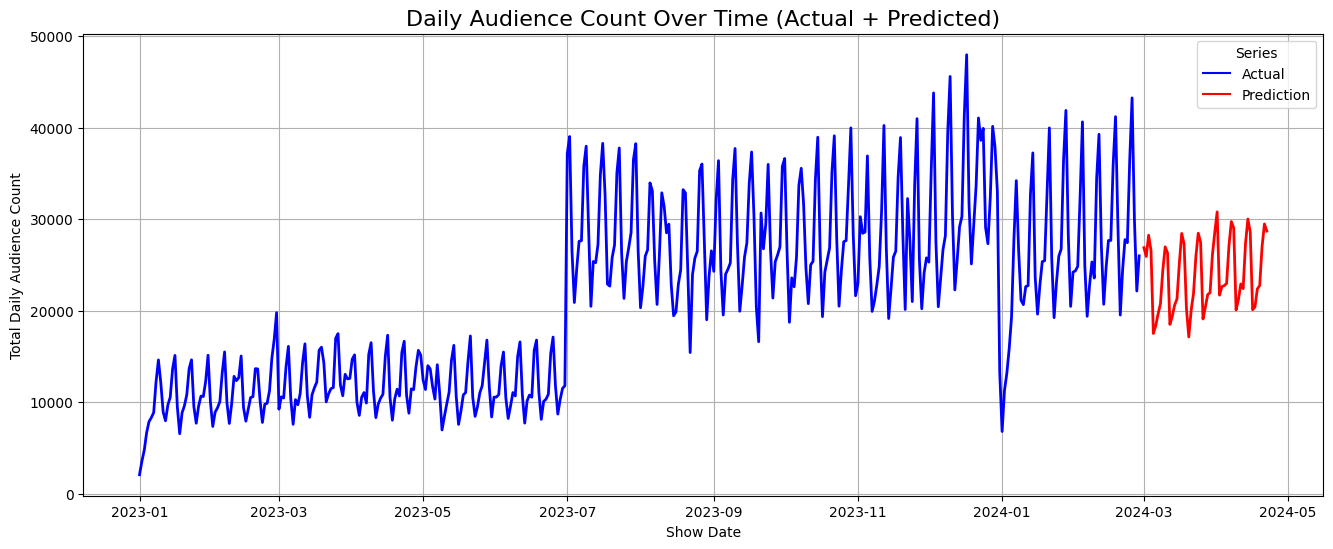

In [142]:
actual_daily = (dataset.groupby("show_date")["audience_count"].sum().reset_index())
actual_daily["type"] = "Actual"

pred_daily = (test.groupby("show_date")["audience_count"].sum().reset_index())
pred_daily["type"] = "Prediction"

ts = pd.concat([actual_daily, pred_daily], axis=0)
ts = ts.sort_values("show_date")

plt.figure(figsize=(16, 6))
sns.lineplot(data=ts, x="show_date", y="audience_count", hue="type", palette={"Actual": "blue", "Prediction": "red"}, linewidth=2)

plt.title("Daily Audience Count Over Time (Actual + Predicted)", fontsize=16)
plt.xlabel("Show Date")
plt.ylabel("Total Daily Audience Count")
plt.legend(title="Series")
plt.grid(True)

plt.show()